# Project: Bankruptcy Prevention

In [3]:
# Business Objective:
# This is a classification project, since the variable to predict is binary (bankruptcy or non-bankruptcy).
# The goal here is to model the probability that a business goes bankrupt from different features.


In [5]:
# The data file contains 7 features about 250 companies
# The data set includes the following variables:
# 1.	industrial_risk: 0=low risk, 0.5=medium risk, 1=high risk.
# 2.	management_risk: 0=low risk, 0.5=medium risk, 1=high risk.
# 3.	financial flexibility: 0=low flexibility, 0.5=medium flexibility, 1=high flexibility.
# 4.	credibility: 0=low credibility, 0.5=medium credibility, 1=high credibility.
# 5.	competitiveness: 0=low competitiveness, 0.5=medium competitiveness, 1=high competitiveness.
# 6.	operating_risk: 0=low risk, 0.5=medium risk, 1=high risk.
# 7.	class: bankruptcy, non-bankruptcy (target variable).

# Step 1 – Load and understand the dataset

In [13]:
# importy requiremts and load data set

import pandas as pd
import numpy as np

df = pd.read_csv("Bankruptcy_prevention_Dataset.csv", sep=";")

In [16]:
# Clean column names
df.columns = df.columns.str.strip()

In [18]:
# Display dataset
print(df.head())

   industrial_risk  management_risk  financial_flexibility  credibility  \
0              0.5              1.0                    0.0          0.0   
1              0.0              1.0                    0.0          0.0   
2              1.0              0.0                    0.0          0.0   
3              0.5              0.0                    0.0          0.5   
4              1.0              1.0                    0.0          0.0   

   competitiveness  operating_risk       class  
0              0.0             0.5  bankruptcy  
1              0.0             1.0  bankruptcy  
2              0.0             1.0  bankruptcy  
3              0.0             1.0  bankruptcy  
4              0.0             1.0  bankruptcy  


In [20]:
# Dataset dimensions
print("Shape:", df.shape)

Shape: (250, 7)


In [22]:
# Data types
print(df.dtypes)

industrial_risk          float64
management_risk          float64
financial_flexibility    float64
credibility              float64
competitiveness          float64
operating_risk           float64
class                        str
dtype: object


In [24]:
# Missing values
print(df.isnull().sum())

industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: int64


In [26]:
# Duplicate records
print("Duplicates:", df.duplicated().sum())

Duplicates: 147


In [28]:
# Target distribution
print(df['class'].value_counts())

class
non-bankruptcy    143
bankruptcy        107
Name: count, dtype: int64


# Step 2 – Dataset visualization

In [38]:
# 1. Dataset overview – duplicates

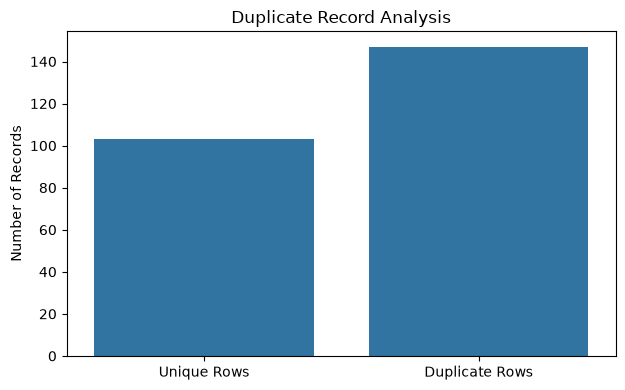

In [36]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 4))


plt.subplot(1, 2, 2)
sns.barplot(
    x=["Unique Rows", "Duplicate Rows"],
    y=[df.drop_duplicates().shape[0], df.duplicated().sum()]
)
plt.title("Duplicate Record Analysis")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()


In [40]:
# 2. Target variable distribution

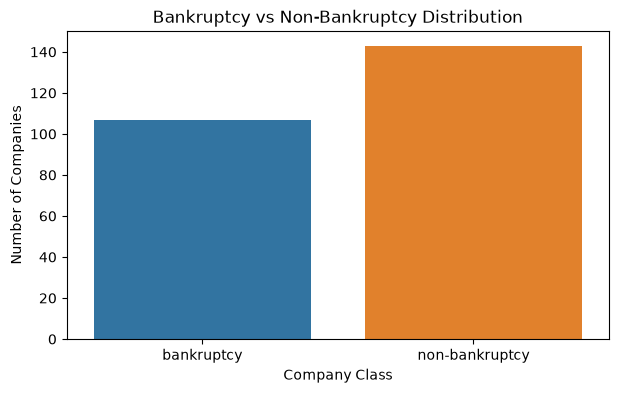

In [42]:

plt.figure(figsize=(7, 4))

sns.countplot(data=df, x="class", hue="class", legend=False)

plt.title("Bankruptcy vs Non-Bankruptcy Distribution")
plt.xlabel("Company Class")
plt.ylabel("Number of Companies")

plt.show()


In [44]:
# 3. Feature distribution

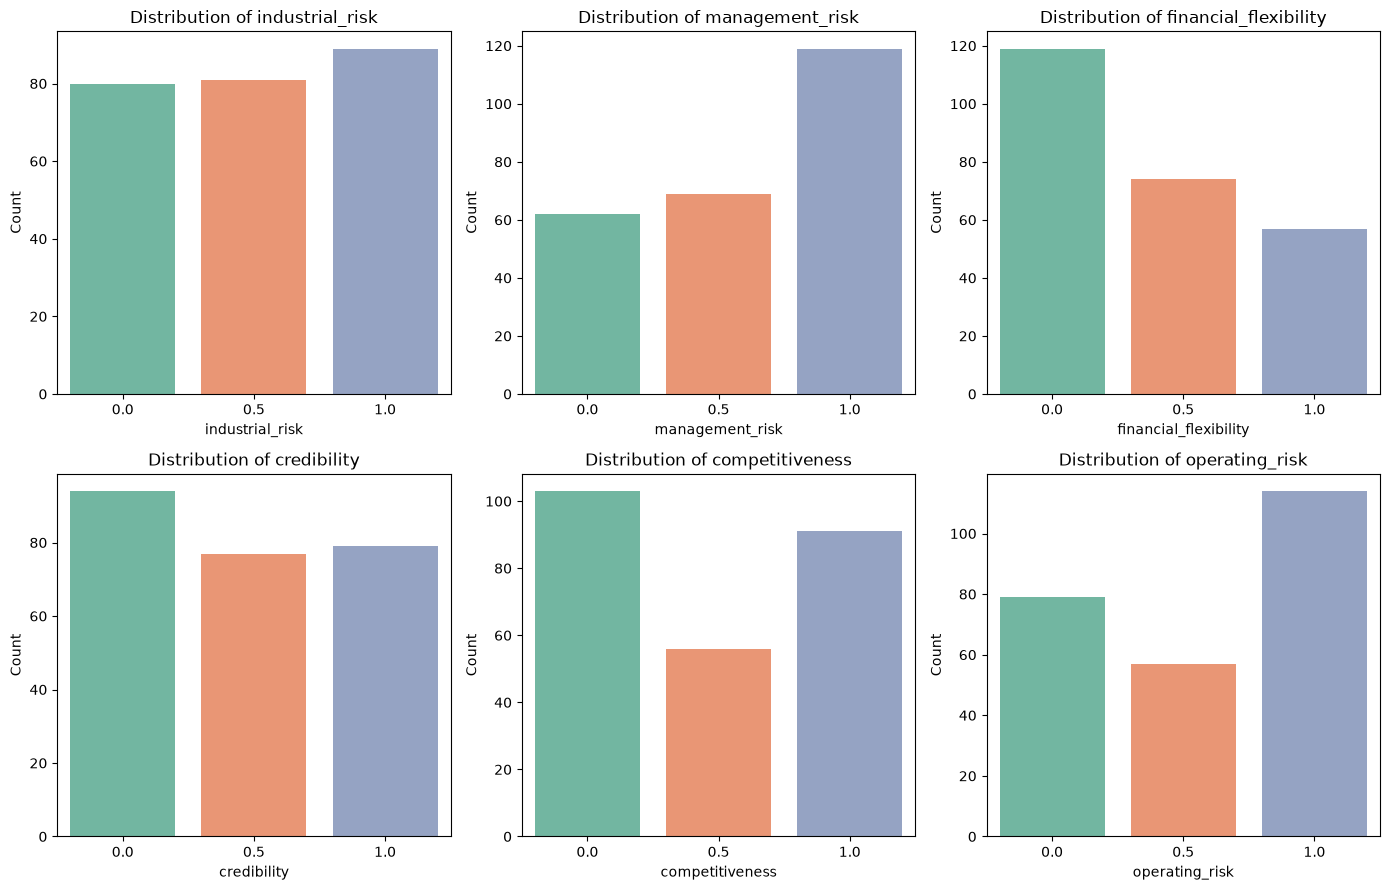

In [53]:

features = df.drop(columns=["class"]).columns

plt.figure(figsize=(14, 9))

for i, col in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.countplot(data=df, x=col, hue=col, palette="Set2", legend=False)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")

plt.tight_layout()
plt.show()


In [49]:
# 4. Correlation heatmap

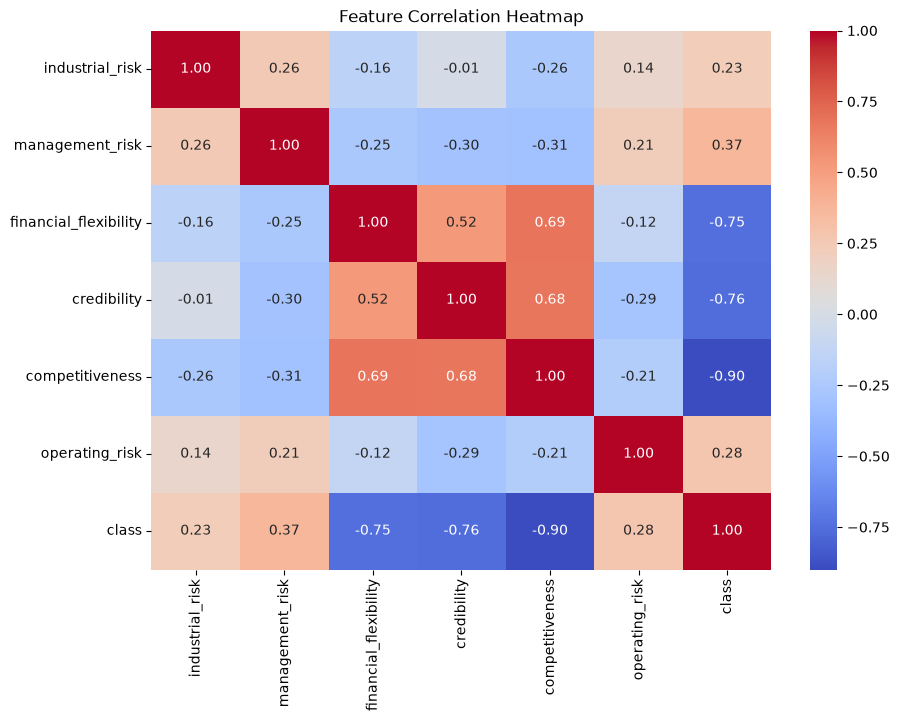

In [51]:

# Encode target temporarily for correlation analysis
df_corr = df.copy()

df_corr["class"] = df_corr["class"].map({
    "bankruptcy": 1,
    "non-bankruptcy": 0
})

plt.figure(figsize=(10, 7))

sns.heatmap(
    df_corr.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()


In [57]:
# Competitiveness, credibility and financial flexibility show the strongest correlations with the target variable. 
# These features may play an important role in predicting bankruptcy. 
# Further model evaluation is required to determine their actual predictive importance.

# Step 3 – Exploratory Data Analysis (EDA)


In [62]:
# Feature-wise Bankruptcy Analysis
# Objective: Understand how each feature influences bankruptcy and non-bankruptcy classification.

In [71]:
# 1 Descriptive statistics

In [73]:

# Statistical summary of all features
print(df.describe())

# Frequency distribution of each feature
for col in df.drop(columns=["class"]).columns:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())


       industrial_risk  management_risk  financial_flexibility  credibility  \
count       250.000000       250.000000             250.000000   250.000000   
mean          0.518000         0.614000               0.376000     0.470000   
std           0.411526         0.410705               0.401583     0.415682   
min           0.000000         0.000000               0.000000     0.000000   
25%           0.000000         0.500000               0.000000     0.000000   
50%           0.500000         0.500000               0.500000     0.500000   
75%           1.000000         1.000000               0.500000     1.000000   
max           1.000000         1.000000               1.000000     1.000000   

       competitiveness  operating_risk  
count       250.000000      250.000000  
mean          0.476000        0.570000  
std           0.440682        0.434575  
min           0.000000        0.000000  
25%           0.000000        0.000000  
50%           0.500000        0.500000  
7

In [76]:
# 2 Feature-wise bankruptcy distribution

In [78]:
# visualize how bankruptcy and non-bankruptcy companies are distributed across all six features

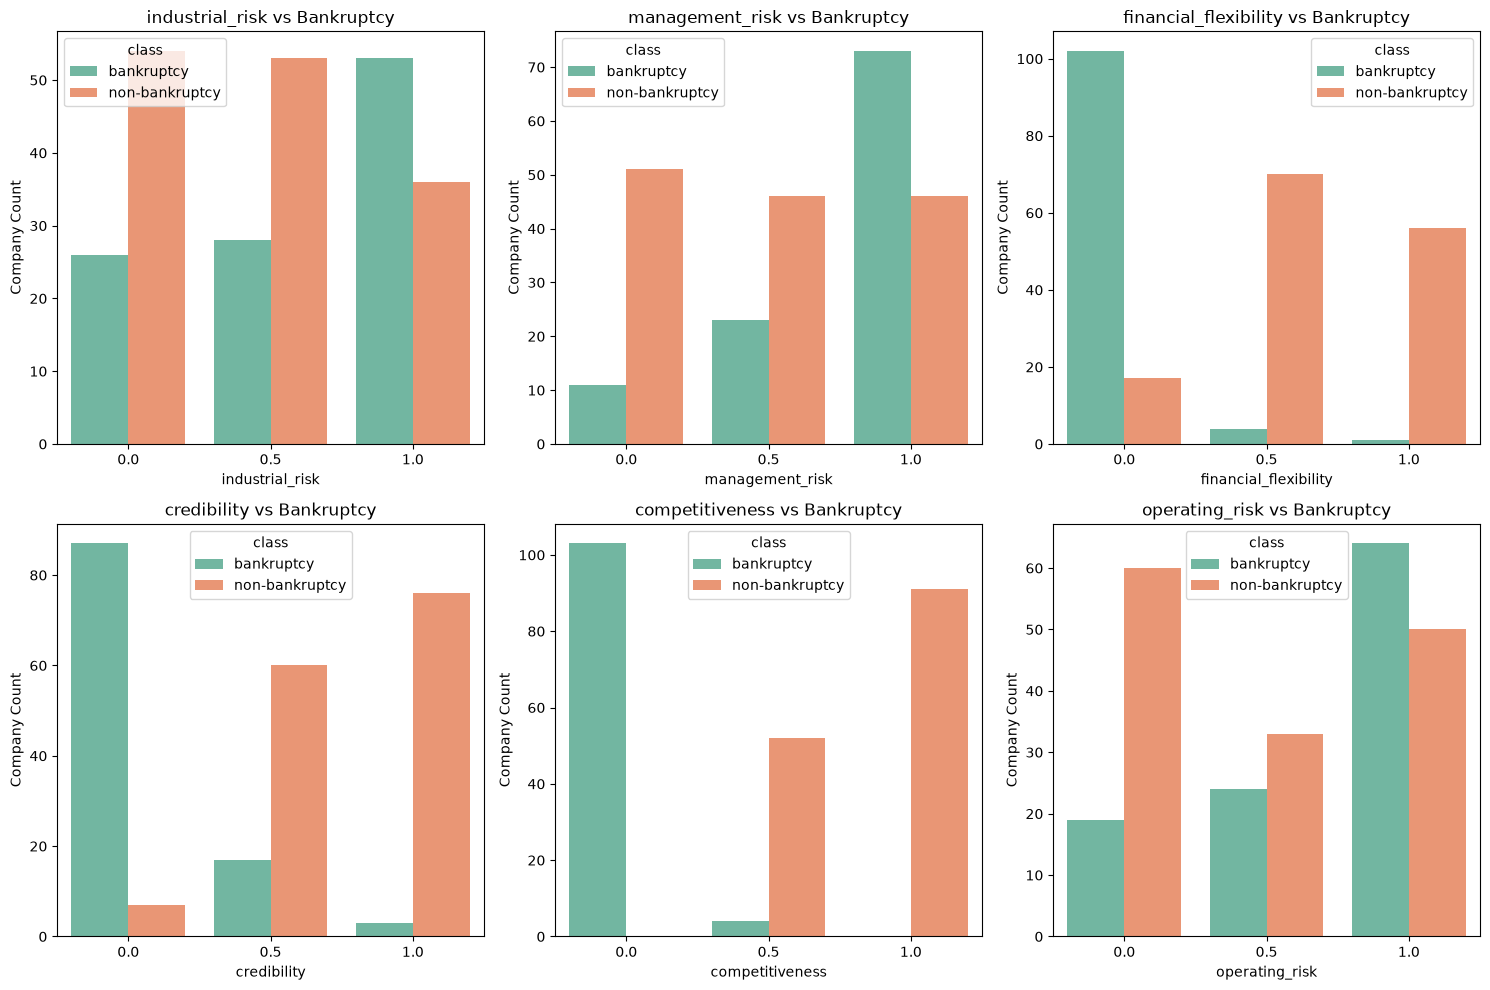

In [80]:

features = df.drop(columns=["class"]).columns

plt.figure(figsize=(15, 10))

for i, col in enumerate(features, 1):
    plt.subplot(2, 3, i)

    sns.countplot(
        data=df,
        x=col,
        hue="class",
        palette="Set2"
    )

    plt.title(f"{col} vs Bankruptcy")
    plt.xlabel(col)
    plt.ylabel("Company Count")

plt.tight_layout()
plt.show()


In [83]:
# 3 Bankruptcy percentage by feature

In [85]:
# shows the percentage of bankruptcy companies at each feature level.

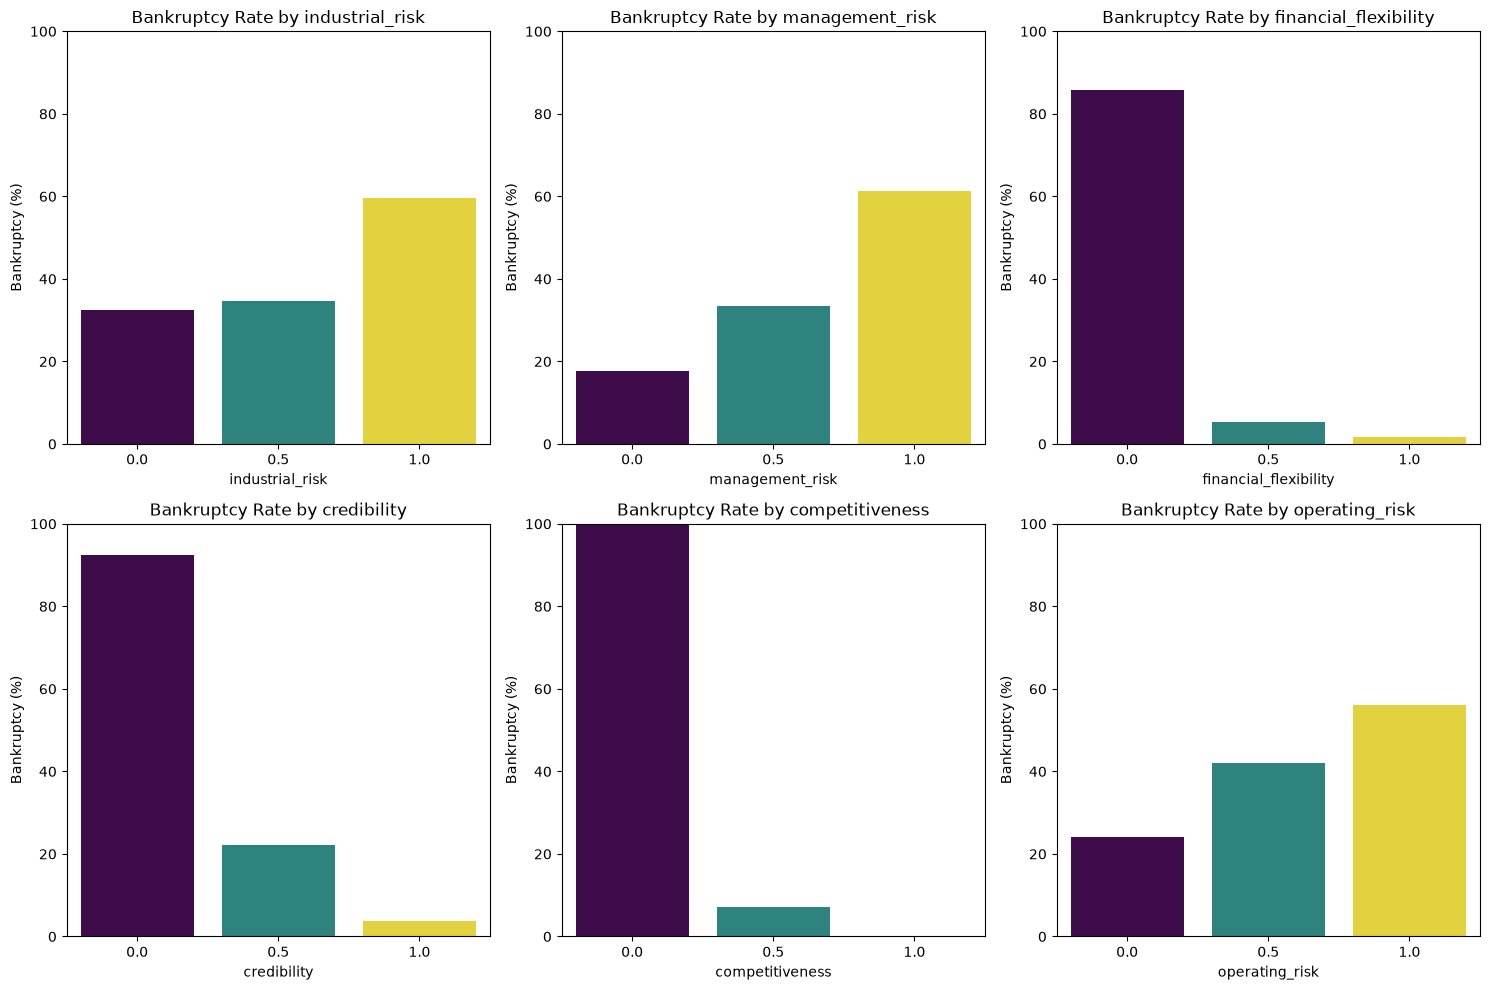

In [87]:

df_analysis = df.copy()

df_analysis["bankruptcy_flag"] = (
    df_analysis["class"] == "bankruptcy"
).astype(int)

plt.figure(figsize=(15, 10))

for i, col in enumerate(features, 1):
    plt.subplot(2, 3, i)

    rate = df_analysis.groupby(col)["bankruptcy_flag"].mean() * 100

    sns.barplot(
        x=rate.index,
        y=rate.values,
        hue=rate.index,
        palette="viridis",
        legend=False
    )

    plt.title(f"Bankruptcy Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Bankruptcy (%)")
    plt.ylim(0, 100)

plt.tight_layout()
plt.show()


# Step 3 – Data Cleaning & Duplicate Analysis

In [94]:
# Objective: Identify duplicate records and understand whether removing them will affect bankruptcy classification.
# dataset contains 250 records and previously we identified 147 duplicate rows.

In [99]:
# 1 Check duplicate records

In [101]:

# Total records
print("Original Shape:", df.shape)

# Count duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Count unique rows
print("Unique Rows:", df.drop_duplicates().shape[0])

# Display duplicate records
duplicates = df[df.duplicated(keep=False)]

print(duplicates.sort_values(by=list(df.columns)))


Original Shape: (250, 7)
Duplicate Rows: 147
Unique Rows: 103
     industrial_risk  management_risk  financial_flexibility  credibility  \
107              0.0              0.0                    0.5          0.5   
215              0.0              0.0                    0.5          0.5   
116              0.0              0.0                    0.5          0.5   
224              0.0              0.0                    0.5          0.5   
180              0.0              0.0                    0.5          0.5   
..               ...              ...                    ...          ...   
232              1.0              1.0                    1.0          1.0   
166              1.0              1.0                    1.0          1.0   
195              1.0              1.0                    1.0          1.0   
111              1.0              1.0                    1.0          1.0   
219              1.0              1.0                    1.0          1.0   

     competit

In [103]:
# 2 Check duplicate feature combinations with different target classes

In [105]:
# Two companies can have identical feature values but different bankruptcy outcomes.

In [107]:

features = df.drop(columns=["class"]).columns.tolist()

# Group identical feature combinations
duplicate_analysis = (
    df.groupby(features)["class"]
    .agg(["count", "nunique"])
    .reset_index()
)

# Same features but different target classes
conflicting_records = duplicate_analysis[
    duplicate_analysis["nunique"] > 1
]

print("Repeated feature combinations:",
      (duplicate_analysis["count"] > 1).sum())

print("Conflicting feature combinations:",
      conflicting_records.shape[0])

print(conflicting_records)


Repeated feature combinations: 74
Conflicting feature combinations: 0
Empty DataFrame
Columns: [industrial_risk, management_risk, financial_flexibility, credibility, competitiveness, operating_risk, count, nunique]
Index: []


In [111]:
# 3 Visualize duplicate records

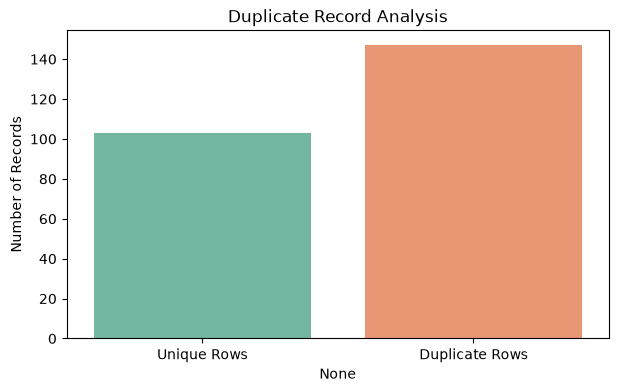

In [113]:

duplicate_counts = pd.Series({
    "Unique Rows": df.drop_duplicates().shape[0],
    "Duplicate Rows": df.duplicated().sum()
})

plt.figure(figsize=(7, 4))

sns.barplot(
    x=duplicate_counts.index,
    y=duplicate_counts.values,
    hue=duplicate_counts.index,
    palette="Set2",
    legend=False
)

plt.title("Duplicate Record Analysis")
plt.ylabel("Number of Records")
plt.show()


In [116]:
# 4 Compare target distribution before and after removing exact duplicates

                Original  After Duplicate Removal
class                                            
non-bankruptcy      57.2                75.728155
bankruptcy          42.8                24.271845


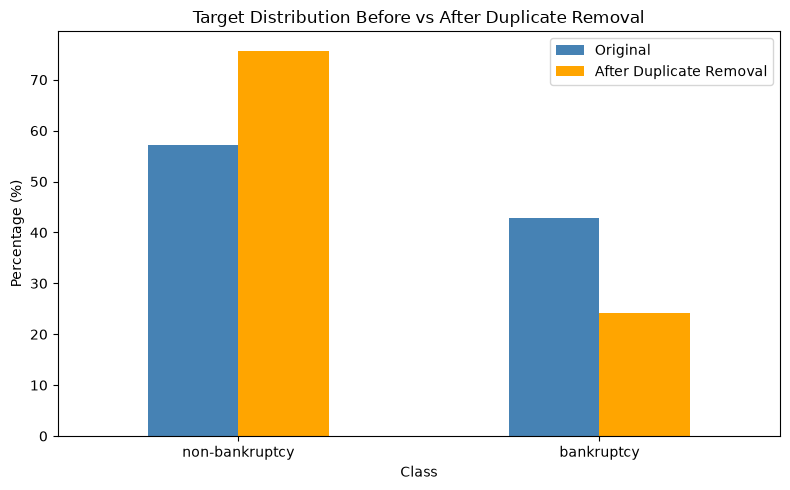

In [118]:

df_unique = df.drop_duplicates()

comparison = pd.DataFrame({
    "Original": df["class"].value_counts(normalize=True) * 100,
    "After Duplicate Removal": 
        df_unique["class"].value_counts(normalize=True) * 100
})

print(comparison)

comparison.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "orange"]
)

plt.title("Target Distribution Before vs After Duplicate Removal")
plt.ylabel("Percentage (%)")
plt.xlabel("Class")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()


In [121]:
# 5 – Duplicate removal decision

In [123]:

df_unique = df.drop_duplicates()

print("Original Dataset:", df.shape)
print("After Removing Duplicates:", df_unique.shape)

print("\nOriginal Target Distribution:")
print(df["class"].value_counts())

print("\nAfter Duplicate Removal:")
print(df_unique["class"].value_counts())


Original Dataset: (250, 7)
After Removing Duplicates: (103, 7)

Original Target Distribution:
class
non-bankruptcy    143
bankruptcy        107
Name: count, dtype: int64

After Duplicate Removal:
class
non-bankruptcy    78
bankruptcy        25
Name: count, dtype: int64


In [127]:
# Percentage comparison

                Before Removal (%)  After Removal (%)
class                                                
non-bankruptcy                57.2              75.73
bankruptcy                    42.8              24.27


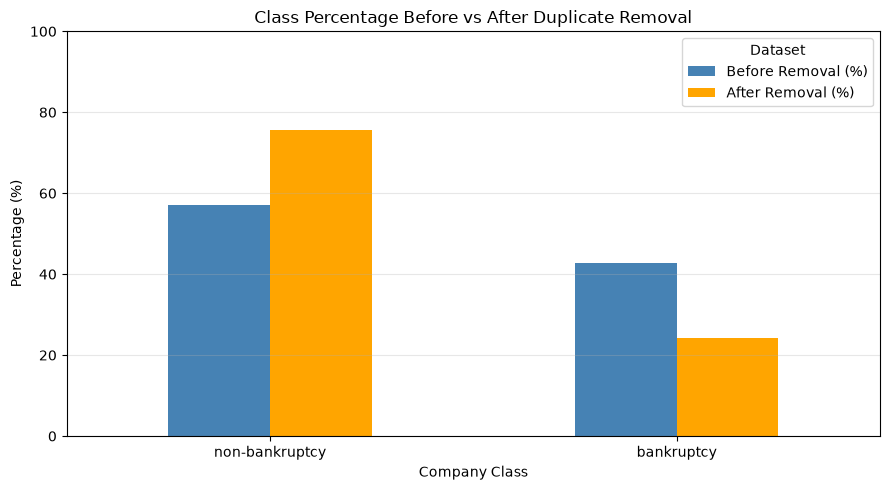

In [129]:

df_unique = df.drop_duplicates()

# Calculate percentage distribution
comparison = pd.DataFrame({
    "Before Removal (%)": df["class"].value_counts(normalize=True) * 100,
    "After Removal (%)": df_unique["class"].value_counts(normalize=True) * 100
})

print(comparison.round(2))

# Visualization
comparison.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "orange"]
)

plt.title("Class Percentage Before vs After Duplicate Removal")
plt.xlabel("Company Class")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Dataset")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [131]:
# After removing exact duplicate rows, 
# the bankruptcy percentage decreased from 42.8% to 24.27%, 
# while non-bankruptcy increased from 57.2% to 75.73%.

# This indicates that duplicate removal significantly changes the target distribution. 
# Therefore, all 250 records are retained until duplicate provenance is verified.

# Step 4 – Data Preprocessing

In [138]:
# Objective: Prepare features and target variable for machine learning.

In [142]:
# 1 Encode target variable

# Our target is categorical - 

# Bankruptcy → 1
# Non-bankruptcy → 0

In [144]:

# Retain original 250 records
df_model = df.copy()

# Encode target variable
df_model["class"] = df_model["class"].map({
    "bankruptcy": 1,
    "non-bankruptcy": 0
})

print(df_model.head())
print("\nTarget distribution:")
print(df_model["class"].value_counts())

print("\nMissing values:")
print(df_model.isnull().sum())


   industrial_risk  management_risk  financial_flexibility  credibility  \
0              0.5              1.0                    0.0          0.0   
1              0.0              1.0                    0.0          0.0   
2              1.0              0.0                    0.0          0.0   
3              0.5              0.0                    0.0          0.5   
4              1.0              1.0                    0.0          0.0   

   competitiveness  operating_risk  class  
0              0.0             0.5      1  
1              0.0             1.0      1  
2              0.0             1.0      1  
3              0.0             1.0      1  
4              0.0             1.0      1  

Target distribution:
class
0    143
1    107
Name: count, dtype: int64

Missing values:
industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: 

In [147]:
# 2 – Separate Independent and Dependent Variables

In [149]:
# Objective: Separate input features (X) and target variable (y) for machine learning.

In [151]:

# Independent variables
X = df_model.drop(columns=["class"])

# Dependent variable
y = df_model["class"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("\nIndependent Variables:")
print(X.head())

print("\nTarget Variable:")
print(y.head())


X Shape: (250, 6)
y Shape: (250,)

Independent Variables:
   industrial_risk  management_risk  financial_flexibility  credibility  \
0              0.5              1.0                    0.0          0.0   
1              0.0              1.0                    0.0          0.0   
2              1.0              0.0                    0.0          0.0   
3              0.5              0.0                    0.0          0.5   
4              1.0              1.0                    0.0          0.0   

   competitiveness  operating_risk  
0              0.0             0.5  
1              0.0             1.0  
2              0.0             1.0  
3              0.0             1.0  
4              0.0             1.0  

Target Variable:
0    1
1    1
2    1
3    1
4    1
Name: class, dtype: int64


In [153]:
# X contains six input features.
# y contains the bankruptcy classification.

# These will be used for model training and prediction.

In [155]:
# 3 – Train-Test Split

In [157]:
# Objective: Divide the dataset into training and testing sets to evaluate model performance on unseen data.

# We will use an 80:20 split.
# - 80% → Training (200 records)
# - 20% → Testing (50 records)

In [159]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (200, 6)
X_test: (50, 6)
y_train: (200,)
y_test: (50,)


In [161]:
# 4 Visualize train-test distribution

Train-Test Percentage Distribution:

                Training  Testing
Non-bankruptcy      57.0     58.0
Bankruptcy          43.0     42.0


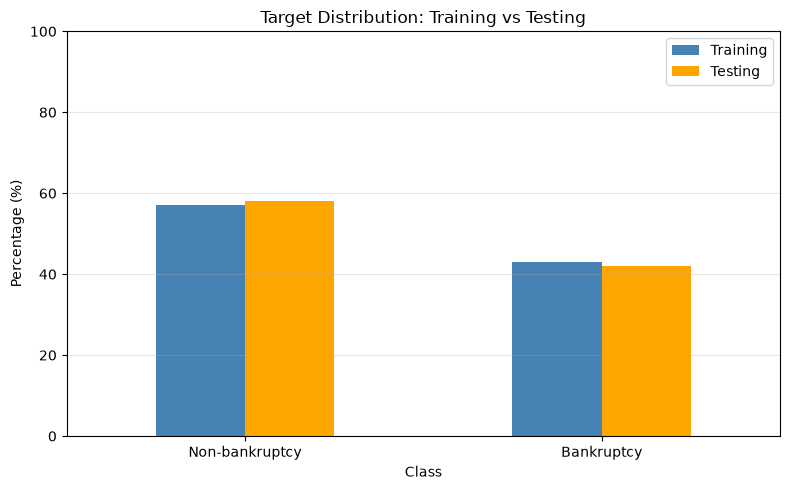

In [165]:

split_data = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True) * 100,
    "Testing": y_test.value_counts(normalize=True) * 100
})

split_data.index = ["Non-bankruptcy", "Bankruptcy"]

# Print percentage distribution
print("Train-Test Percentage Distribution:\n")
print(split_data.round(2))

# Visualization
split_data.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "orange"]
)

plt.title("Target Distribution: Training vs Testing")
plt.ylabel("Percentage (%)")
plt.xlabel("Class")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Step 5 – Feature Scaling

In [169]:
# Objective: Understand whether our dataset requires feature scaling before training machine learning models

In [171]:
# 1 Check feature ranges

In [173]:

print("Feature Minimum Values:\n")
print(X.min())

print("\nFeature Maximum Values:\n")
print(X.max())

print("\nFeature Standard Deviation:\n")
print(X.std())


Feature Minimum Values:

industrial_risk          0.0
management_risk          0.0
financial_flexibility    0.0
credibility              0.0
competitiveness          0.0
operating_risk           0.0
dtype: float64

Feature Maximum Values:

industrial_risk          1.0
management_risk          1.0
financial_flexibility    1.0
credibility              1.0
competitiveness          1.0
operating_risk           1.0
dtype: float64

Feature Standard Deviation:

industrial_risk          0.411526
management_risk          0.410705
financial_flexibility    0.401583
credibility              0.415682
competitiveness          0.440682
operating_risk           0.434575
dtype: float64


In [175]:
# Minimum and maximum show feature ranges.

# Standard deviation shows how much values vary.

# Our features currently have values of 0, 0.5 and 1.

In [178]:
# 2 Visualize feature distributions

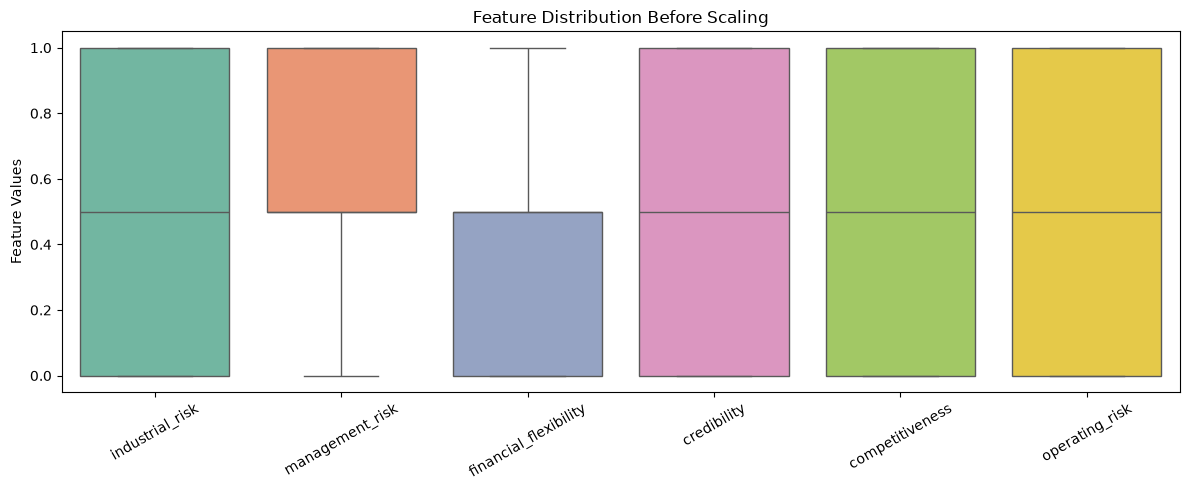

In [180]:

plt.figure(figsize=(12, 5))

sns.boxplot(data=X, palette="Set2")

plt.title("Feature Distribution Before Scaling")
plt.ylabel("Feature Values")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [184]:
# 3 Do we need scaling

In [188]:
# Our features already share the same numerical range (0 to 1).
# We can first establish baseline models using the original features.

In [190]:
# Decision Tree and Random Forest do not require scaling.

# Logistic Regression and SVM can benefit from scaling in general, but our features are already on the same scale.

# Scaling these already bounded features may not provide meaningful improvement.

# Step 6 – Model Building (Classification)

In [196]:
# Objective: Train multiple classification algorithms and compare their performance to identify the best model for bankruptcy prediction.

In [200]:
# We will start with five models:
# 1. Logistic Regression - 	Linear
# 2. Decision Tree - Tree-based
# 3. Random Forest - 	Ensemble – Bagging
# 4. Support Vector Machine (SVM) - Kernel-based
# 5. K-Nearest Neighbors (KNN) - 	Distance-based
# 6. Gradient Boosting - Ensemble – Boosting

In [223]:
# Model	Purpose
# Logistic Regression	- Predicts probability of bankruptcy
# Decision Tree	- Learns decision rules
# Random Forest	- Combines multiple decision trees
# SVM	- Finds an optimal classification boundary
# KNN	- Classifies using nearest observations
# Gradient Boosting - 	Sequential error correction

In [208]:
# 1 Import and initialize all algorithms

In [227]:

# Import classification algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier



In [229]:
# Initialize models

models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    
    "Random Forest": RandomForestClassifier(random_state=42),
    
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    
    "SVM": CalibratedClassifierCV(
    SVC(),
    method="sigmoid",
    cv=5,
    ensemble=False
    ),
    
    "KNN": KNeighborsClassifier()
}

print("Total Models:", len(models))
print("\nModels initialized successfully!")

for name in models:
    print(name)


Total Models: 6

Models initialized successfully!
Logistic Regression
Decision Tree
Random Forest
Gradient Boosting
SVM
KNN


In [215]:
# 2 Train all six models

In [231]:

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully!")


Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!
SVM trained successfully!
KNN trained successfully!


In [219]:
# 3 Generate predictions

In [233]:

predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    print(f"\n{name} Predictions:")
    print(y_pred)



Logistic Regression Predictions:
[1 0 0 0 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 1 1 1 1 1 1 1
 1 0 0 1 1 1 0 0 0 0 0 0 0]

Decision Tree Predictions:
[1 0 0 0 0 1 1 0 1 0 0 1 1 0 1 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 1 1 1 1 1 1 1
 1 0 0 1 1 1 0 0 0 0 0 0 0]

Random Forest Predictions:
[1 0 0 0 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 1 1 1 1 1 1 1
 1 0 0 1 1 1 0 0 0 0 0 0 0]

Gradient Boosting Predictions:
[1 0 0 0 0 1 1 0 1 0 0 1 1 0 1 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 1 1 1 1 1 1 1
 1 0 0 1 1 1 0 0 0 0 0 0 0]

SVM Predictions:
[1 0 0 0 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 1 1 1 1 1 1 1
 1 0 0 1 1 1 0 0 0 0 0 0 0]

KNN Predictions:
[1 0 0 0 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 1 1 1 0 0 1 0 0 0 0 1 1 1 1 1 1 1
 1 0 0 1 1 1 0 0 0 0 0 0 0]


# Step 7 – Model Evaluation

In [237]:
# Objective: Evaluate all six trained models and identify which performs best at predicting bankruptcy.

# We will evaluate using six metrics:
# 1. Accuracy
# 2. Precision
# 3. Recall
# 4. F1-score
# 5. ROC-AUC
# 6. Confusion Matrix

In [240]:
# 1 Calculate evaluation metrics

In [242]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))


                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression      1.00     1.0000     1.0    1.0000   1.0000
1        Decision Tree      0.98     0.9545     1.0    0.9767   0.9828
2        Random Forest      1.00     1.0000     1.0    1.0000   1.0000
3    Gradient Boosting      0.98     0.9545     1.0    0.9767   0.9828
4                  SVM      1.00     1.0000     1.0    1.0000   1.0000
5                  KNN      1.00     1.0000     1.0    1.0000   1.0000


In [ ]:
#  Performance comparison
# Model	                Accuracy	Precision	Recall	F1
# Logistic Regression	100%	100%	100%	100%
# Decision Tree	         98%	95.45%	100%	97.67%
# Random Forest	        100%	100%	100%	100%
# Gradient Boosting	     98%	95.45%	100%	97.67%
# SVM	                100%	100%	100%	100%
# KNN	                100%	100%	100%	100%

In [263]:
# Key observations

# 1. Four models achieved 100% accuracy: Logistic Regression, Random Forest, SVM and KNN.
# 2. Decision Tree and Gradient Boosting achieved 98% accuracy.
# 3. All six models achieved 100% bankruptcy recall on this test split.
# 4. ROC-AUC is 1.0 for four models, indicating perfect separation on this test set.

In [ ]:
# Important concern – Possible Data Leakage
# Before selecting the winning model, we need to investigate something important.

# our earlier finding

# - 250 original records.
# - 103 unique complete records.
# - 74 repeated feature combinations.
# - Zero conflicting feature combinations.

In [245]:
# 2 Visualize model comparison

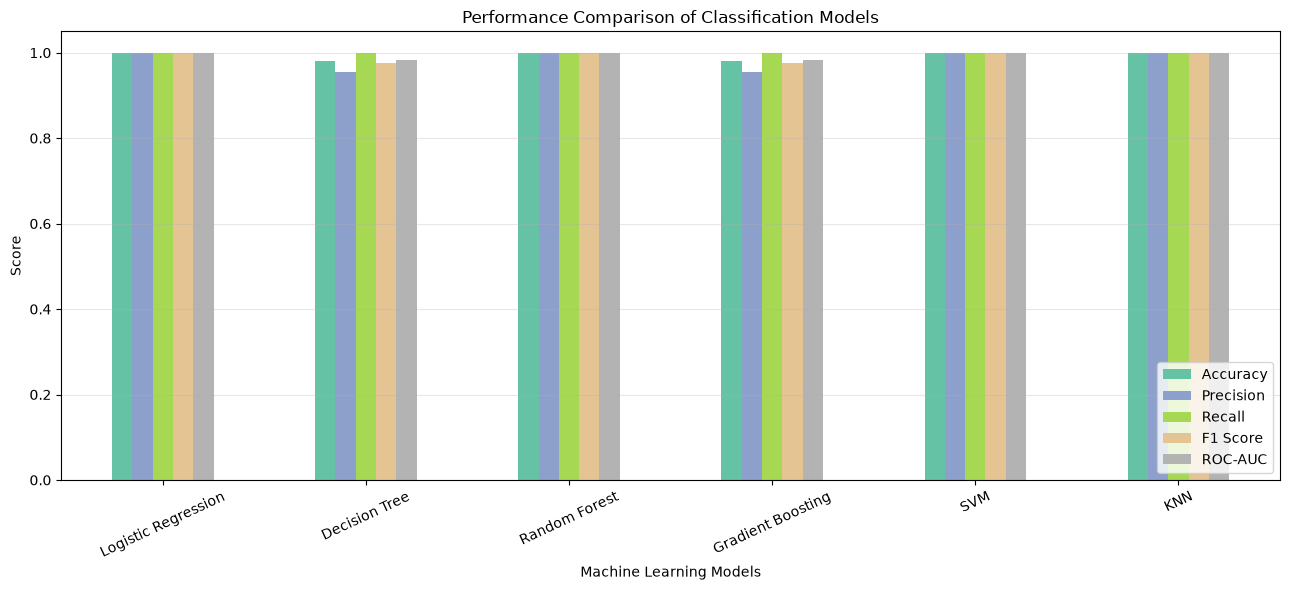

In [247]:

metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6),
    colormap="Set2"
)

plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1.05)
plt.xticks(rotation=25)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [250]:
# 3 Understand the evaluation metrics

In [252]:
# Metric	- What it tells us
# Accuracy	- Overall correct predictions
# Precision	- How many predicted bankruptcies were actually bankrupt
# Recall	- How many actual bankruptcies were detected
# F1-score	- Balance between precision and recall
# ROC-AUC	- Ability to distinguish between both classes

In [254]:
# Important for this project - 

# Bankruptcy Recall is particularly important. A low recall means the model is missing companies that actually go bankrupt.

In [257]:
# 4 Confusion Matrix – All six models

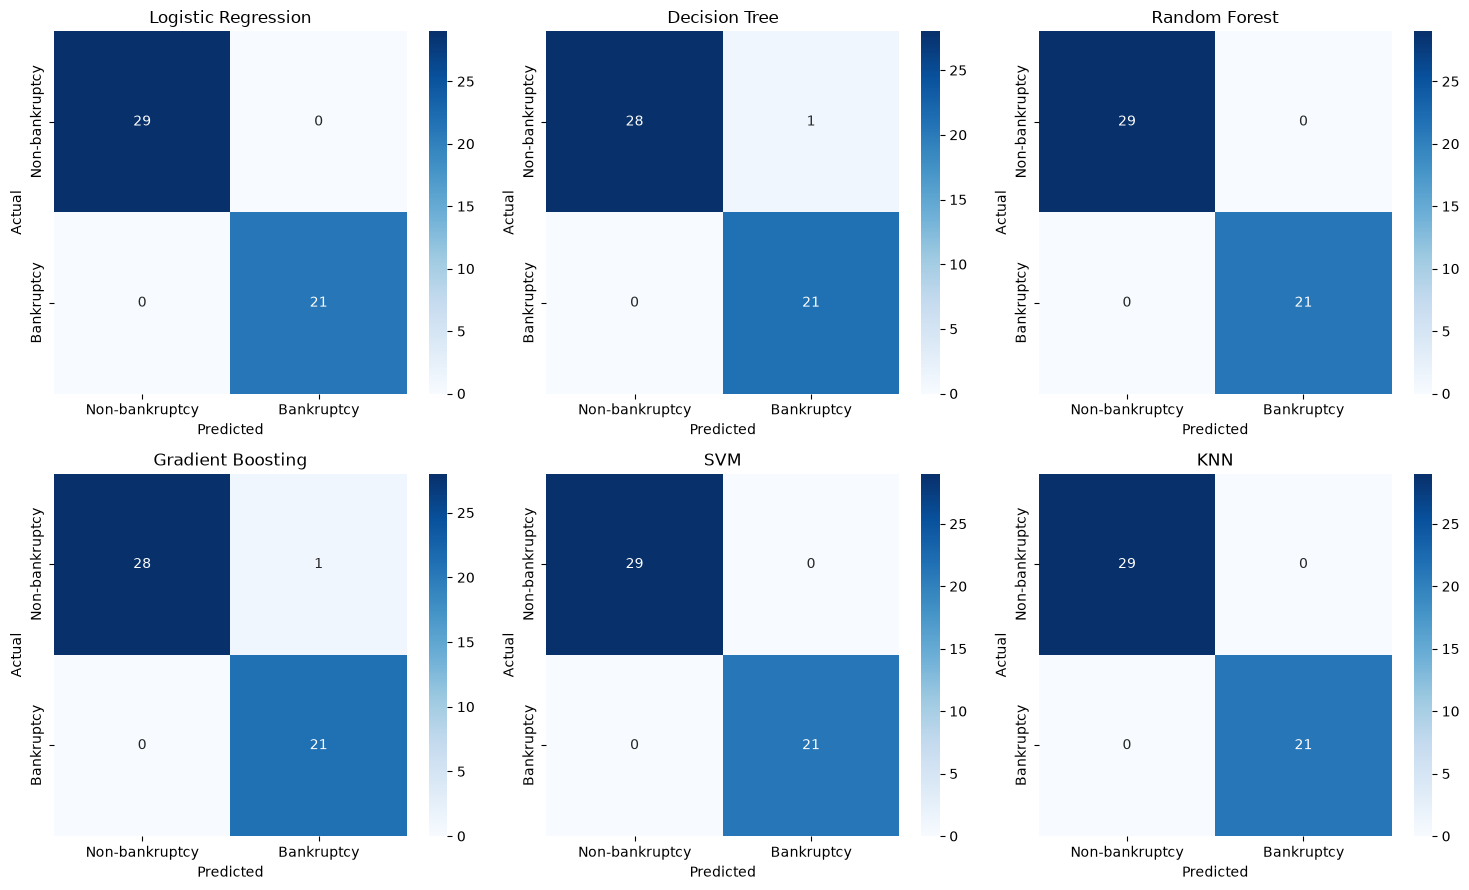

In [259]:

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (name, model) in zip(axes.flat, models.items()):

    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Non-bankruptcy", "Bankruptcy"],
        yticklabels=["Non-bankruptcy", "Bankruptcy"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [261]:
# Notes:

# - True Negative (TN): Correctly predicted non-bankruptcy.
# - True Positive (TP): Correctly predicted bankruptcy.
# - False Positive (FP): Predicted bankruptcy, but actually non-bankruptcy.
# - False Negative (FN): Predicted non-bankruptcy, but actually bankruptcy.

In [266]:
# Because we used a random train-test split, identical feature combinations may appear in both training and testing datasets.

In [268]:
# This can artificially inflate model performance, We should verify this before accepting 100% accuracy.

In [273]:
# 4 Check train-test feature overlap

In [277]:
# Checks whether identical company profiles occur in both datasets.
# Common combinations can make test predictions easier.
# We should avoid this overlap when evaluating generalization to unseen profiles.

In [279]:
# If overlap exists, we will use StratifiedGroupKFold to separate identical feature combinations 
# between training and testing while maintaining class proportions as closely as possible.

In [275]:

# Identify identical feature combinations in train and test

train_groups = set(
    map(tuple, X_train.to_numpy())
)

test_groups = set(
    map(tuple, X_test.to_numpy())
)

overlap = train_groups.intersection(test_groups)

print("Unique feature combinations in training:",
      len(train_groups))

print("Unique feature combinations in testing:",
      len(test_groups))

print("Common combinations across train and test:",
      len(overlap))


Unique feature combinations in training: 95
Unique feature combinations in testing: 35
Common combinations across train and test: 27


In [281]:
# output confirms that 27 feature combinations are present in both training and testing datasets.

In [283]:
# Metric	                                  Result
# Training unique combinations	              95
# Testing unique combinations	              35
# Common combinations	                      27
# Test combinations overlapping training	77.14%

In [285]:
# If the testing data contains the same six feature values, the model has already encountered that profile during training.
# This can make predictions look artificially accurate.

In [287]:
# Our next objective: Evaluate models on feature combinations they have never seen during training.

# 6 – Group-based Train-Test Split

In [291]:
# We will use StratifiedGroupKFold.
# It provides:
# - Separation of identical feature combinations.
# - Approximately balanced target proportions.
# - Five-fold cross-validation structure.

In [294]:
# Create groups

In [296]:

from sklearn.model_selection import StratifiedGroupKFold

# Assign identical feature combinations to the same group
groups = pd.MultiIndex.from_frame(X).factorize()[0]

print("Total unique groups:", len(np.unique(groups)))


Total unique groups: 103


In [299]:
# Create new train-test split

In [301]:

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Select the first fold
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Distribution:")
print(y_train.value_counts())

print("\nTesting Distribution:")
print(y_test.value_counts())


Training Shape: (200, 6)
Testing Shape: (50, 6)

Training Distribution:
class
0    115
1     85
Name: count, dtype: int64

Testing Distribution:
class
0    28
1    22
Name: count, dtype: int64


In [304]:
# Verify no feature overlap

In [306]:

train_groups = set(groups[train_idx])
test_groups = set(groups[test_idx])

overlap = train_groups.intersection(test_groups)

print("Common groups:", len(overlap))

assert len(overlap) == 0, "Data leakage detected!"

print("No feature combination overlap detected.")


Common groups: 0
No feature combination overlap detected.


In [309]:
# Retrain and evaluate all six models

In [311]:
# We must retrain because the training dataset has changed.

In [313]:

from sklearn.base import clone

results_grouped = []
predictions_grouped = {}

for name, model in models.items():

    new_model = clone(model)

    new_model.fit(X_train, y_train)

    y_pred = new_model.predict(X_test)
    y_prob = new_model.predict_proba(X_test)[:, 1]

    predictions_grouped[name] = y_pred

    results_grouped.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_grouped_df = pd.DataFrame(results_grouped)

print(results_grouped_df.round(4))


                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression      0.98        1.0  0.9545    0.9767   0.9968
1        Decision Tree      1.00        1.0  1.0000    1.0000   1.0000
2        Random Forest      1.00        1.0  1.0000    1.0000   1.0000
3    Gradient Boosting      1.00        1.0  1.0000    1.0000   1.0000
4                  SVM      0.98        1.0  0.9545    0.9767   1.0000
5                  KNN      0.98        1.0  0.9545    0.9767   0.9740


In [316]:
# Visualize performance

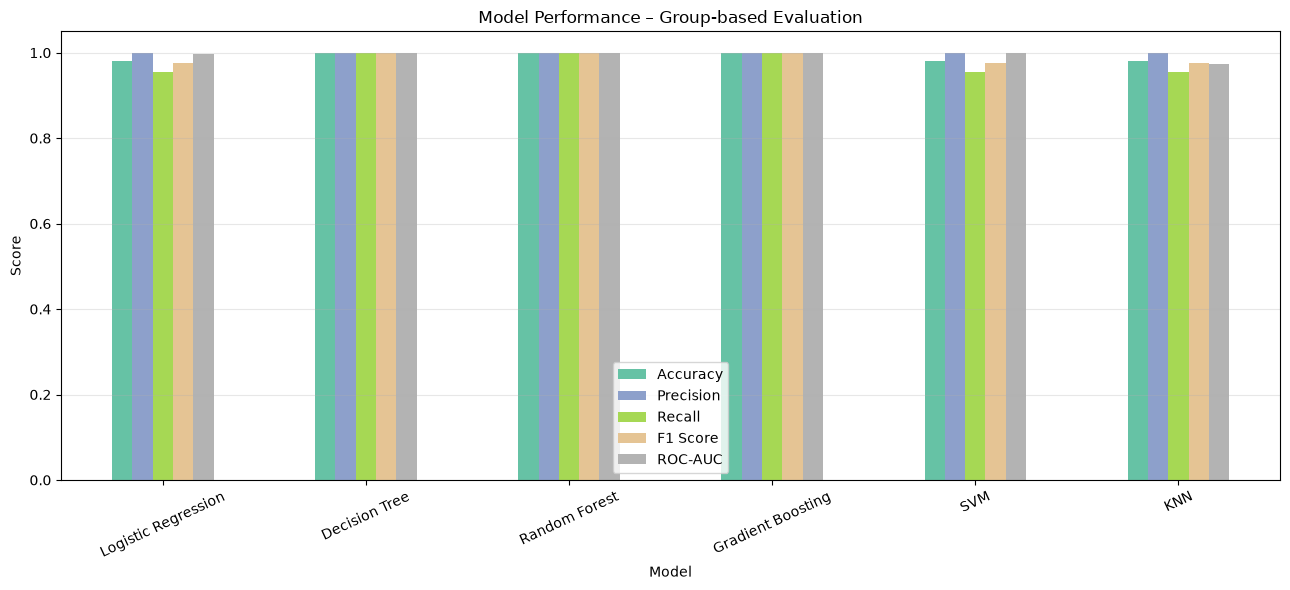

In [318]:

results_grouped_df.set_index("Model").plot(
    kind="bar",
    figsize=(13, 6),
    colormap="Set2"
)

plt.title("Model Performance – Group-based Evaluation")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [320]:
# Important: This is a more reliable test of generalization to unseen feature combinations, 
# but one fold is still only one evaluation. We will later use all five folds for a more robust comparison.

# Step 7 – Group-based Model Evaluation: Results

In [327]:
# our new evaluation is much more reliable for testing unseen feature combinations.

In [329]:
# Updated model comparison

# Model               Accuracy	   Precision	Recall	    F1-score	ROC-AUC
# Logistic Regression	98%	        100%	    95.45%	      97.67%	99.68%
# Decision Tree	        100%	    100%	    100%	        100%	100%
# Random Forest	        100%	    100%	    100%	        100%	100%
# Gradient Boosting	    100%	    100%	    100%	        100%	100%
# SVM	                 98%	    100%	    95.45%	      97.67%	100%
# KNN	                 98%	    100%	    95.45%	      97.67%	97.40%

In [332]:
# Key observations
# 1. Decision Tree, Random Forest and Gradient Boosting achieved 100% across all five metrics.
# 2. Logistic Regression, SVM and KNN missed one actual bankruptcy company each.
# 3. All six models achieved 100% precision, meaning none of their predicted bankruptcy cases were false alarms on this test set.
# 4. No identical feature combinations appeared in both training and testing datasets.

In [334]:
# Current leading models: Decision Tree, Random Forest and Gradient Boosting.

In [339]:
# Important: Don't finalize the winning model yet
# Our dataset has only 103 unique feature combinations. 
# A single 80:20 split is not enough to establish that a model will consistently achieve 100% performance.


In [341]:
# We will perform 5-Fold Stratified Group Cross-Validation.

# This will:
# - Test all 103 feature groups across five folds.
# - Ensure identical feature combinations never cross between training and validation.
# - Provide average performance across five evaluations.
# - Help identify whether the 100% scores are consistent.

# Step 8 – 5-Fold Cross-Validation

In [347]:
# 1 Evaluate all six models across five folds

In [ ]:
# Notes
# - Each model is trained and evaluated five times.
# - We calculate the average score across all five folds.
# - Higher scores are generally better.
# - Pay particular attention to bankruptcy Recall.

In [349]:

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.base import clone

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    fold_scores = []

    for train_idx, test_idx in sgkf.split(X, y, groups):

        X_tr, X_val = X.iloc[train_idx], X.iloc[test_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[test_idx]

        clf = clone(model)
        clf.fit(X_tr, y_tr)

        y_pred = clf.predict(X_val)

        fold_scores.append({
            "Accuracy": accuracy_score(y_val, y_pred),
            "Precision": precision_score(y_val, y_pred, zero_division=0),
            "Recall": recall_score(y_val, y_pred, zero_division=0),
            "F1 Score": f1_score(y_val, y_pred, zero_division=0)
        })

    scores_df = pd.DataFrame(fold_scores)

    cv_results.append({
        "Model": name,
        "Accuracy": scores_df["Accuracy"].mean(),
        "Precision": scores_df["Precision"].mean(),
        "Recall": scores_df["Recall"].mean(),
        "F1 Score": scores_df["F1 Score"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

print(cv_results_df.round(4))


                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     0.996     1.0000  0.9909    0.9953
1        Decision Tree     0.964     0.9589  0.9636    0.9580
2        Random Forest     0.984     1.0000  0.9636    0.9800
3    Gradient Boosting     0.964     0.9589  0.9636    0.9580
4                  SVM     0.996     1.0000  0.9909    0.9953
5                  KNN     0.988     0.9833  0.9909    0.9867


In [351]:
# 2 Visualize cross-validation results

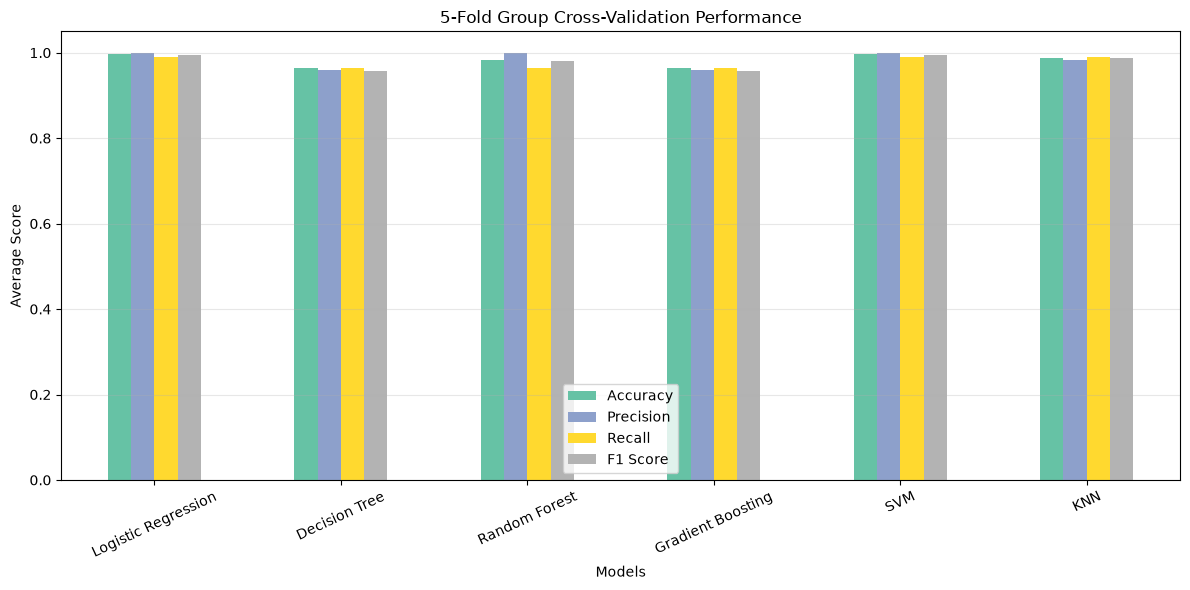

In [353]:

cv_results_df.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6),
    colormap="Set2"
)

plt.title("5-Fold Group Cross-Validation Performance")
plt.ylabel("Average Score")
plt.xlabel("Models")
plt.ylim(0, 1.05)
plt.xticks(rotation=25)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [356]:
# Model comparison

# Model	Accuracy	Precision	Recall	F1-score
# Logistic Regression	99.60%	100%	99.09%	99.53%
# Decision Tree	96.40%	95.89%	96.36%	95.80%
# Random Forest	98.40%	100%	96.36%	98.00%
# Gradient Boosting	96.40%	95.89%	96.36%	95.80%
# SVM	99.60%	100%	99.09%	99.53%
# KNN	98.80%	98.33%	99.09%	98.67%

In [358]:
# Key observations
# 1. Logistic Regression: Highest accuracy and F1-score.
# 2. SVM: Matches Logistic Regression performance.
# 3. KNN: Strong bankruptcy recall.
# 4. Random Forest: Perfect precision but slightly lower recall.
# 5. Decision Tree and Gradient Boosting perform comparatively lower.

In [360]:
# Logistic Regression - 99.60%
# Average cross-validation accuracy
# - Precision: 100%
# - Bankruptcy Recall: 99.09%
# - F1-score: 99.53%

In [363]:
# However, we should not finalize the model yet. 
# This is a very small dataset with repeated profiles, so these scores may not represent performance on genuinely new companies.

# Step 9 – Hyperparameter Tuning

In [368]:
# Objective: Find better model configurations and check whether performance can improve. We will start with Logistic Regression.

In [370]:
# 1 Hyperparameter tuning using GridSearchCV

In [ ]:
# Notes
# - C: Controls regularization strength.
# - solver: Optimization algorithm.
# - class_weight: Adjusts importance of classes.
# - GridSearchCV: Tests different parameter combinations.
# - scoring="f1": Selects parameters based on F1-score.

In [372]:

from sklearn.model_selection import GridSearchCV

# Define parameter combinations
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["lbfgs", "liblinear"],
    "class_weight": [None, "balanced"]
}

# Initialize model
lr = LogisticRegression(max_iter=1000, random_state=42)

# Grid search with grouped cross-validation
grid_search = GridSearchCV(
    estimator=lr,
    param_grid=param_grid,
    cv=sgkf,
    scoring="f1",
    n_jobs=-1
)

# Fit model
grid_search.fit(X, y, groups=groups)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)


Best Parameters: {'C': 0.1, 'class_weight': None, 'solver': 'lbfgs'}
Best CV F1 Score: 0.9953488372093023


In [375]:
# Parameter	Best value	Meaning
# C	0.1	Stronger regularization
# class_weight	None	No class weighting
# solver	lbfgs	Optimization algorithm
# Best CV F1	99.53%	Average cross-validation F1

In [377]:
# Observation: The tuned Logistic Regression achieved approximately 99.53% F1-score, which is consistent with our earlier cross-validation result.

In [380]:
# 3 Next – Tune SVM

In [382]:
# SVM was another top-performing model, so let's optimize it.

In [ ]:
# Notes:
# - C: Controls the penalty for classification errors.
# - kernel: Tests linear, RBF and polynomial boundaries.
# - gamma: Controls the influence of individual training observations.
# - GridSearchCV: Finds the best parameter combination.

In [384]:

from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GridSearchCV

# SVM parameter grid
param_grid_svm = {
    "estimator__C": [0.1, 1, 10, 100],
    "estimator__kernel": ["linear", "rbf", "poly"],
    "estimator__gamma": ["scale", "auto"]
}

# Base SVM with probability calibration
svm_model = CalibratedClassifierCV(
    SVC(),
    method="sigmoid",
    cv=5,
    ensemble=False
)

# Grid Search
grid_svm = GridSearchCV(
    estimator=svm_model,
    param_grid=param_grid_svm,
    cv=sgkf,
    scoring="f1",
    n_jobs=-1
)

# Train
grid_svm.fit(X, y, groups=groups)

print("Best SVM Parameters:", grid_svm.best_params_)
print("Best SVM CV F1 Score:", grid_svm.best_score_)


Best SVM Parameters: {'estimator__C': 0.1, 'estimator__gamma': 'scale', 'estimator__kernel': 'linear'}
Best SVM CV F1 Score: 0.9953488372093023


In [386]:
# Compare tuned models
# Metric	Logistic Regression	SVM
# Best C	0.1	0.1
# Solver	lbfgs	Not applicable
# Kernel	Not applicable	Linear
# Gamma	Not applicable	Scale
# Class weight	None	Default
# CV F1-score	99.53%	99.53%

In [388]:
# Key observations
# 1. Both models achieved identical cross-validation F1-scores.
# 2. SVM selected a linear kernel, indicating a linear decision boundary works well.
# 3. Logistic Regression is easier to interpret and explain.
# 4. Both models are strong candidates for bankruptcy prediction.

In [390]:
# Keep both models as finalists. Logistic Regression is our current preferred model because of its interpretability.

# Step 10 – Final model comparison and selection

In [394]:
# Before selecting the final model, let's compare their five-fold performance using the tuned configurations.

In [406]:
# 1 Compare tuned Logistic Regression and SVM

In [408]:
# Notes:
# - We compare both tuned models on the same group-based holdout set.
# - This is a final holdout comparison, not another cross-validation score.
# - We will select based on recall, precision, F1 and interpretability.

In [399]:

# Best tuned models
best_lr = grid_search.best_estimator_
best_svm = grid_svm.best_estimator_

final_models = {
    "Tuned Logistic Regression": best_lr,
    "Tuned SVM": best_svm
}

comparison_results = []

for name, model in final_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

final_comparison = pd.DataFrame(comparison_results)

print(final_comparison.round(4))



                       Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Tuned Logistic Regression      0.98        1.0  0.9545    0.9767   0.9968
1                  Tuned SVM      0.98        1.0  0.9545    0.9767   0.9968


In [402]:
# Visualize final comparison

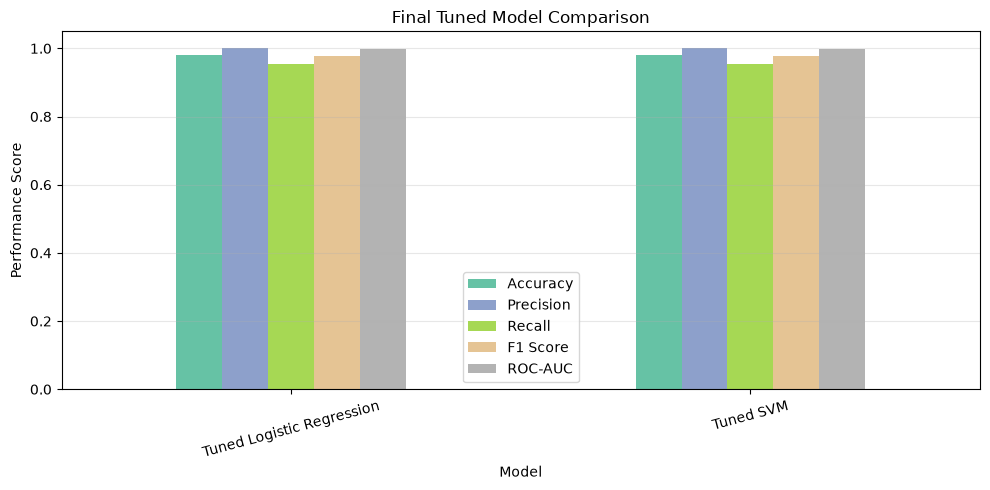

In [404]:

final_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    colormap="Set2"
)

plt.title("Final Tuned Model Comparison")
plt.ylabel("Performance Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [411]:
# Final comparison
# Metric	Logistic Regression	SVM
# Accuracy	98%	    98%
# Precision	100%	100%
# Recall	95.45%	95.45%
# F1-score	97.67%	97.67%
# ROC-AUC	99.68%	99.68%

In [414]:
# Final model selection - Tuned Logistic Regression - 98% - Group-based holdout accuracy

# Reasons:
# - Excellent classification performance.
# - Provides interpretable coefficients.
# - Supports bankruptcy probability prediction.
# - Lightweight and easy to deploy using Streamlit.

In [417]:
# SVM remains a strong alternative.

In [419]:
# Tuned Logistic Regression was selected as the final candidate due to its strong predictive performance, 
# interpretability and computational efficiency. It achieved 98% accuracy, 100% precision, 95.45% recall and 99.68% ROC-AUC 
# on the group-based holdout set.

# Step 11 – Final Model Preparation

In [423]:
# Now we will prepare the selected model for deployment.

In [425]:
# 1 Train the final model
# We will use the best hyperparameters identified by GridSearchCV and train on the complete dataset.

In [427]:

# Select best Logistic Regression model
final_model = grid_search.best_estimator_

# Train using complete dataset
final_model.fit(X, y)

print("Final model trained successfully!")

print("\nBest Parameters:")
print(grid_search.best_params_)


Final model trained successfully!

Best Parameters:
{'C': 0.1, 'class_weight': None, 'solver': 'lbfgs'}


In [430]:
# 2 Test probability prediction

In [434]:
# Notes
# - predict() predicts the classification.
# - predict_proba() estimates the probability of each class.
# - We will use these probabilities in our Streamlit application.

In [432]:

# Sample company data
sample_company = pd.DataFrame([{
    "industrial_risk": 0.5,
    "management_risk": 1.0,
    "financial_flexibility": 0.0,
    "credibility": 0.0,
    "competitiveness": 0.0,
    "operating_risk": 0.5
}])

# Predict class
prediction = final_model.predict(sample_company)[0]

# Predict probabilities
probability = final_model.predict_proba(sample_company)[0]

print("Prediction:",
      "Bankruptcy" if prediction == 1 else "Non-bankruptcy")

print("Non-bankruptcy Probability:", round(probability[0] * 100, 2), "%")
print("Bankruptcy Probability:", round(probability[1] * 100, 2), "%")


Prediction: Bankruptcy
Non-bankruptcy Probability: 18.4 %
Bankruptcy Probability: 81.6 %


In [436]:
# Interpretation: The model predicts bankruptcy for this company's feature profile, with an estimated bankruptcy probability of 81.6%.

In [438]:
# Remember: This is a model estimate, not a confirmed financial outcome.

# Step 12 – Save the trained model

In [443]:
# We need to save the trained model so Streamlit can load it without retraining every time.

In [445]:
# 1 Install and import Joblib

In [454]:
# Notes:
# - joblib.dump() saves the trained model.
# - joblib.load() loads the saved model.
# - .pkl stores the trained model object.

In [447]:

import joblib

# Save trained model
joblib.dump(final_model, "bankruptcy_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [450]:
# 2 Load and verify the saved model

In [452]:

loaded_model = joblib.load("bankruptcy_model.pkl")

prediction = loaded_model.predict(sample_company)[0]
probability = loaded_model.predict_proba(sample_company)[0]

print("Prediction:",
      "Bankruptcy" if prediction == 1 else "Non-bankruptcy")

print("Bankruptcy Probability:",
      round(probability[1] * 100, 2), "%")


Prediction: Bankruptcy
Bankruptcy Probability: 81.6 %


# Step 13 – Prepare Streamlit deployment

In [461]:
# Our next task is to build a user interface where users can enter company risk parameters and receive bankruptcy predictions.

In [ ]:
# Proposed project structure:

bankruptcy-prevention/
│
├── data/
│   └── bankruptcy_dataset.csv
│
├── models/
│   └── bankruptcy_model.pkl
│
├── app.py
├── train_model.py
├── requirements.txt
└── README.md

In [ ]:
# Install Streamlit

# Run in your terminal or Jupyter Notebook: pip install streamlit joblib

In [ ]:
# 2 Prepare project structure

# Create the following folders and files:

bankruptcy-prevention/
│
├── models/
│   └── bankruptcy_model.pkl
│
├── app.py
└── requirements.txt

In [463]:
# Move your saved bankruptcy_model.pkl into the models folder.

In [465]:
# 3 Create app.py – Application setup


In [ ]:
# Notes:
# - streamlit: Creates the web interface.
# - joblib: Loads our trained ML model.
# - set_page_config(): Configures the application.
# - st.title(): Displays the application heading.
# - st.divider(): Adds a visual separator.

In [ ]:
import streamlit as st
import pandas as pd
import joblib
import base64
from pathlib import Path
from datetime import datetime

# ---------------------------------------------------------
# Page Configuration
# ---------------------------------------------------------
st.set_page_config(
    page_title="Bankruptcy Prevention System",
    page_icon="🏦",
    layout="wide",
    initial_sidebar_state="expanded"
)

# ---------------------------------------------------------
# Paths & Helper Functions
# ---------------------------------------------------------
BASE_DIR = Path(__file__).resolve().parent
MODEL_PATH = BASE_DIR / "models" / "bankruptcy_model.pkl"
IMAGES_DIR = BASE_DIR / "images"

def get_image_path(image_name: str):
    """Finds image_name with .png, .jpg, or .jpeg extension inside images/ folder."""
    for ext in [".png", ".jpg", ".jpeg", ".webp"]:
        candidate = IMAGES_DIR / f"{image_name}{ext}"
        if candidate.exists():
            return candidate
    return None

@st.cache_data
def get_base64_image(image_path_str: str):
    """Encodes local image to Base64 and caches it so page switches stay instant."""
    with open(image_path_str, "rb") as f:
        return base64.b64encode(f.read()).decode()

def set_page_background(image_name: str, overlay_opacity: float = 0.80):
    """Sets a full-screen background image with frosted white overlay, black sidebar, and high-contrast text."""
    img_path = get_image_path(image_name)
    bg_css = ""
    if img_path:
        b64_str = get_base64_image(str(img_path))
        ext = img_path.suffix.lstrip(".").lower()
        if ext == "jpg":
            ext = "jpeg"
        bg_css = f"""
background-image: linear-gradient(
    rgba(255, 255, 255, {overlay_opacity}),
    rgba(255, 255, 255, {overlay_opacity})
), url("data:image/{ext};base64,{b64_str}");
background-size: cover;
background-position: center;
background-repeat: no-repeat;
background-attachment: fixed;
"""
    else:
        bg_css = "background-color: #f8fafc;"

    st.markdown(f"""
<style>
.stApp {{
    {bg_css}
    color: #0f172a !important;
}}

/* Force dark high-contrast text across headings, labels, markdown, and metrics in the main area */
.stApp h1, .stApp h2, .stApp h3, .stApp h4, .stApp h5, .stApp h6 {{
    color: #090d16 !important;
    font-weight: 700 !important;
}}
.stApp p, .stApp span, .stApp label, .stApp li, .stApp div[data-testid="stMarkdownContainer"] {{
    color: #111827 !important;
}}
.stApp small, .stApp .stCaption, [data-testid="stCaptionContainer"] p {{
    color: #334155 !important;
    font-weight: 500 !important;
}}

/* Metric labels & numbers */
[data-testid="stMetricLabel"] p {{
    color: #1e293b !important;
    font-weight: 600 !important;
}}
[data-testid="stMetricValue"] div {{
    color: #090d16 !important;
    font-weight: 800 !important;
}}

/* Frosted white containers & cards in main area */
div[data-testid="stVerticalBlockBorderWrapper"],
div[data-testid="stMetric"] {{
    background-color: rgba(255, 255, 255, 0.93) !important;
    border: 1px solid #cbd5e1 !important;
    border-radius: 12px;
    padding: 14px 18px;
    box-shadow: 0 3px 12px rgba(15, 23, 42, 0.08);
}}

/* Deep BLACK Sidebar with White/Silver Text */
section[data-testid="stSidebar"] {{
    background: linear-gradient(180deg, #090d16 0%, #020205 100%) !important;
    border-right: 1px solid #1e293b;
}}
section[data-testid="stSidebar"] h1,
section[data-testid="stSidebar"] h2,
section[data-testid="stSidebar"] h3,
section[data-testid="stSidebar"] h4,
section[data-testid="stSidebar"] h5,
section[data-testid="stSidebar"] h6,
section[data-testid="stSidebar"] div[data-testid="stMarkdownContainer"] h2 {{
    color: #ffffff !important;
    text-shadow: 0 2px 4px rgba(0,0,0,0.5);
}}
section[data-testid="stSidebar"] p,
section[data-testid="stSidebar"] span,
section[data-testid="stSidebar"] label,
section[data-testid="stSidebar"] div[data-testid="stMarkdownContainer"] {{
    color: #f1f5f9 !important;
}}
section[data-testid="stSidebar"] .stCaption,
section[data-testid="stSidebar"] [data-testid="stCaptionContainer"] p {{
    color: #94a3b8 !important;
    font-weight: 500 !important;
}}
section[data-testid="stSidebar"] .stDivider {{
    border-color: #334155 !important;
}}

/* Black Sidebar radio buttons/Navigation style */
section[data-testid="stSidebar"] div[data-baseweb="radio"] label {{
    background: rgba(255, 255, 255, 0.05);
    padding: 8px 12px;
    border-radius: 8px;
    margin-bottom: 6px;
    border: 1px solid rgba(255, 255, 255, 0.05);
    transition: all 0.2s ease;
}}
section[data-testid="stSidebar"] div[data-baseweb="radio"] label:hover {{
    background: rgba(255, 255, 255, 0.12) !important;
    border-color: rgba(255, 255, 255, 0.2);
}}
section[data-testid="stSidebar"] div[data-baseweb="radio"] div[data-testid="stMarkdownContainer"] p {{
    color: #ffffff !important;
    font-weight: 500 !important;
}}

/* Input boxes & selectboxes readable light theme in main contents */
div[data-baseweb="select"] > div,
div[data-baseweb="input"] > div {{
    background-color: #ffffff !important;
    color: #0f172a !important;
    border-color: #94a3b8 !important;
}}
div[data-baseweb="select"] span {{
    color: #0f172a !important;
}}

/* Keep Hero Banner text crisp white on dark gradient */
.hero-banner {{
    background: linear-gradient(135deg, rgba(15, 32, 39, 0.95) 0%, rgba(32, 58, 67, 0.95) 50%, rgba(44, 83, 100, 0.95) 100%);
    padding: 28px 32px;
    border-radius: 14px;
    margin-bottom: 18px;
    box-shadow: 0 4px 15px rgba(0,0,0,0.20);
}}
.hero-banner h1 {{
    color: #ffffff !important;
    margin-bottom: 6px;
    font-size: 2.1rem;
}}
.hero-banner p {{
    color: #e2e8f0 !important;
    font-size: 1.05rem;
    margin-bottom: 0;
}}

/* Keep Primary Button text white */
button[kind="primary"] p, button[kind="primary"] span {{
    color: #ffffff !important;
    font-weight: 600 !important;
}}
/* Download button dark text on white */
div[data-testid="stDownloadButton"] button {{
    background-color: #ffffff !important;
    border: 1px solid #64748b !important;
}}
div[data-testid="stDownloadButton"] button p {{
    color: #0f172a !important;
    font-weight: 600 !important;
}}

/* Custom high-impact WHITE TEXT result cards */
.white-alert-container {{
    border-radius: 12px;
    padding: 20px 24px;
    margin-bottom: 18px;
    box-shadow: 0 4px 14px rgba(0,0,0,0.18);
}}
.white-alert-container h3, .white-alert-container p, .white-alert-container span, .white-alert-container strong {{
    color: #ffffff !important;
    text-shadow: 0 1px 3px rgba(0,0,0,0.3) !important;
}}

/* Dark High-Contrast Visual Wrapper for Observations, Upload Guide & Quick Guide */
.dark-card-container {{
    background: linear-gradient(135deg, #1e293b 0%, #0f172a 100%) !important;
    border: 1.5px solid #334155 !important;
    border-radius: 12px !important;
    padding: 20px 24px !important;
    box-shadow: 0 4px 14px rgba(0,0,0,0.25) !important;
    margin-bottom: 18px !important;
}}
.dark-card-container h3,
.dark-card-container h4,
.dark-card-container h5,
.dark-card-container p,
.dark-card-container span,
.dark-card-container strong,
.dark-card-container li,
.dark-card-container ul {{
    color: #ffffff !important;
    text-shadow: 0 1px 2px rgba(0,0,0,0.4) !important;
}}
.dark-card-container code {{
    background-color: rgba(255, 255, 255, 0.15) !important;
    color: #fde047 !important;
    padding: 2px 6px;
    border-radius: 4px;
}}
.dark-card-container .warning-header {{
    color: #fbcfe8 !important;
    font-weight: 700 !important;
}}
.dark-card-container .strength-header {{
    color: #a7f3d0 !important;
    font-weight: 700 !important;
}}
.dark-card-container .info-highlight {{
    color: #e0f2fe !important;
    font-size: 0.95rem;
    line-height: 1.5;
    margin-bottom: 12px !important;
}}

/* Dark card & 100% WHITE text for st.file_uploader */
[data-testid="stFileUploader"] {{
    background: linear-gradient(135deg, #1e293b 0%, #0f172a 100%) !important;
    border: 1.5px solid #334155 !important;
    border-radius: 0 0 12px 12px !important;
    padding: 18px !important;
}}
[data-testid="stFileUploader"] section {{
    background-color: rgba(255, 255, 255, 0.06) !important;
    border: 1.5px dashed #64748b !important;
    border-radius: 10px !important;
}}
[data-testid="stFileUploader"] span,
[data-testid="stFileUploader"] small,
[data-testid="stFileUploader"] p,
[data-testid="stFileUploader"] div,
[data-testid="stFileUploader"] label,
[data-testid="stFileUploader"] svg {{
    color: #ffffff !important;
    fill: #ffffff !important;
}}
[data-testid="stFileUploader"] button {{
    background-color: #2563eb !important;
    color: #ffffff !important;
    border: none !important;
    font-weight: 600 !important;
}}
[data-testid="stFileUploader"] button span,
[data-testid="stFileUploader"] button p {{
    color: #ffffff !important;
}}
</style>
""", unsafe_allow_html=True)

def show_result_banner(title: str, message: str, is_risk: bool):
    """Renders a custom high-contrast alert card with 100% white text on a colorful background."""
    bg_color = "linear-gradient(135deg, #b91c1c 0%, #991b1b 100%)" if is_risk else "linear-gradient(135deg, #15803d 0%, #166534 100%)"
    border_color = "#991b1b" if is_risk else "#166534"
    html = (
        f'<div class="white-alert-container" style="background: {bg_color}; border: 1.5px solid {border_color};">'
        f'<h3 style="margin: 0 0 8px 0; font-size: 1.35rem; font-weight: 700; color: #ffffff !important;">{title}</h3>'
        f'<p style="margin: 0; font-size: 1.05rem; font-weight: 500; line-height: 1.45; color: #ffffff !important;">{message}</p>'
        f'</div>'
    )
    st.markdown(html, unsafe_allow_html=True)

def render_pie_chart(non_bankruptcy_pct: float, bankruptcy_pct: float, title: str = "Risk Proportion Split"):
    """Renders a clean Donut/Pie chart using pure CSS conic-gradient (no plotly/pyplot required)."""
    safe_angle = max(0.0, min(100.0, non_bankruptcy_pct))
    html_chart = (
        f'<div style="background:rgba(255,255,255,0.95); border:1px solid #cbd5e1; border-radius:12px; padding:18px; text-align:center;">'
        f'<div style="font-weight:700; font-size:1.05rem; color:#090d16; margin-bottom:14px;">{title}</div>'
        f'<div style="width:190px; height:190px; border-radius:50%; margin:0 auto 16px auto; background:conic-gradient(#16A34A 0% {safe_angle:.2f}%, #DC2626 {safe_angle:.2f}% 100%); display:flex; align-items:center; justify-content:center;">'
        f'<div style="width:105px; height:105px; background:#ffffff; border-radius:50%; display:flex; flex-direction:column; align-items:center; justify-content:center; box-shadow:inset 0 1px 4px rgba(0,0,0,0.10);">'
        f'<span style="font-size:0.75rem; font-weight:600; color:#334155;">Bankruptcy</span>'
        f'<span style="font-size:1.15rem; font-weight:800; color:#DC2626;">{bankruptcy_pct:.1f}%</span>'
        f'</div></div>'
        f'<div style="display:flex; justify-content:center; gap:20px; font-size:0.9rem; font-weight:600; color:#0f172a;">'
        f'<span><span style="display:inline-block; width:12px; height:12px; background:#16A34A; border-radius:2px; margin-right:6px;"></span>Non-Bankruptcy ({non_bankruptcy_pct:.1f}%)</span>'
        f'<span><span style="display:inline-block; width:12px; height:12px; background:#DC2626; border-radius:2px; margin-right:6px;"></span>Bankruptcy ({bankruptcy_pct:.1f}%)</span>'
        f'</div></div>'
    )
    st.markdown(html_chart, unsafe_allow_html=True)

# ---------------------------------------------------------
# Load Trained Model
# ---------------------------------------------------------
@st.cache_resource
def load_model(model_path: Path):
    return joblib.load(model_path)

try:
    model = load_model(MODEL_PATH)
except FileNotFoundError:
    st.error(f"Model file not found at `{MODEL_PATH}`. Please check your folder path.")
    st.stop()

# ---------------------------------------------------------
# Initialize Session State for History
# ---------------------------------------------------------
if "history" not in st.session_state:
    st.session_state["history"] = []

FEATURE_COLS = [
    "industrial_risk",
    "management_risk",
    "financial_flexibility",
    "credibility",
    "competitiveness",
    "operating_risk"
]

LEVEL_LABELS = {0.0: "0.0 (Low)", 0.5: "0.5 (Medium)", 1.0: "1.0 (High)"}

# ---------------------------------------------------------
# Sidebar Navigation
# ---------------------------------------------------------
with st.sidebar:
    st.markdown("<h2 style='text-align:center; margin-top:4px;'>🏦 FinGuard AI</h2>", unsafe_allow_html=True)
    st.caption("Corporate Solvency & Bankruptcy Risk Intelligence")
    st.divider()

    page = st.radio(
        "Navigation",
        [
            "🏠 Home",
            "🔍 Predict Risk",
            "📂 Batch CSV Upload",
            "🕒 Prediction History"
        ]
    )

    st.divider()
    st.caption("Model Encoding: `0 = Bankruptcy` | `1 = Non-Bankruptcy`")

# ---------------------------------------------------------
# PAGE 1: HOME (Full-Page bank.png Background)
# ---------------------------------------------------------
if page == "🏠 Home":
    set_page_background("bank", overlay_opacity=0.78)

    st.markdown(
        '<div class="hero-banner">'
        '<h1>🏦 Corporate Bankruptcy Prevention System</h1>'
        '<p>Early-warning financial risk assessment powered by Machine Learning across corporate capital, liquidity, governance, and market competitiveness indicators.</p>'
        '</div>',
        unsafe_allow_html=True
    )

    m1, m2, m3 = st.columns(3)
    m1.metric("Risk Indicators", "6 Core Factors")
    m2.metric("Scale Levels", "0.0 | 0.5 | 1.0")
    m3.metric("Assessment Modes", "Single & Batch")

    st.divider()

    col_left, col_right = st.columns([1.3, 1])

    with col_left:
        with st.container(border=True):
            st.subheader("📌 How the System Evaluates Risk")
            st.write(
                "The predictive model analyzes **6 core qualitative financial and operational indicators** "
                "scored at three levels: **0.0 (Low)**, **0.5 (Medium)**, and **1.0 (High)**."
            )
            indicators_df = pd.DataFrame({
                "Indicator": [
                    "Industrial Risk",
                    "Management Risk",
                    "Financial Flexibility",
                    "Credibility",
                    "Competitiveness",
                    "Operating Risk"
                ],
                "Category": [
                    "External Threat",
                    "Governance Threat",
                    "Capital Strength",
                    "Credit Strength",
                    "Market Strength",
                    "Operational Threat"
                ],
                "Impact on Bankruptcy": [
                    "Higher (1.0) increases bankruptcy risk",
                    "Higher (1.0) increases bankruptcy risk",
                    "Lower (0.0) strongly increases bankruptcy risk",
                    "Lower (0.0) strongly increases bankruptcy risk",
                    "Lower (0.0) strongly increases bankruptcy risk",
                    "Higher (1.0) increases bankruptcy risk"
                ]
            })
            st.dataframe(indicators_df, use_container_width=True, hide_index=True)

    with col_right:
        guide_html = (
            '<div class="dark-card-container">'
            '<h3 style="margin:0 0 12px 0; font-size:1.25rem; font-weight:700; color:#ffffff !important;">🚀 Quick Navigation Guide</h3>'
            '<p class="info-highlight"><strong>🔍 Predict Risk:</strong><br>'
            'Test an individual company, inspect Bar & Pie probability charts, review key risk drivers, and download a formal assessment report.</p>'
            '<p class="info-highlight" style="margin-top:12px;"><strong>📂 Batch CSV Upload:</strong><br>'
            'Upload a multi-company CSV file to score an entire portfolio at once and download visual results.</p>'
            '<p class="info-highlight" style="margin-top:12px;"><strong>🕒 Prediction History:</strong><br>'
            'Review, compare, and export all predictions evaluated during your current active session.</p>'
            '</div>'
        )
        st.markdown(guide_html, unsafe_allow_html=True)

# ---------------------------------------------------------
# PAGE 2: SINGLE COMPANY PREDICT (Full-Page cash.png Background)
# ---------------------------------------------------------
elif page == "🔍 Predict Risk":
    set_page_background("cash", overlay_opacity=0.82)

    st.title("🔍 Single Company Bankruptcy Prediction")
    st.write("Evaluate working capital resilience, liquidity flexibility, and operational risk indicators.")

    with st.container(border=True):
        company_name = st.text_input("Company Name / Reference ID", value="Acme Corp Ltd.")

        st.subheader("Company Risk & Strength Indicators")
        col1, col2 = st.columns(2)

        with col1:
            industrial_risk = st.selectbox("Industrial Risk", [0.0, 0.5, 1.0], format_func=LEVEL_LABELS.get)
            management_risk = st.selectbox("Management Risk", [0.0, 0.5, 1.0], format_func=LEVEL_LABELS.get)
            financial_flexibility = st.selectbox("Financial Flexibility", [0.0, 0.5, 1.0], index=2, format_func=LEVEL_LABELS.get)

        with col2:
            credibility = st.selectbox("Credibility", [0.0, 0.5, 1.0], index=2, format_func=LEVEL_LABELS.get)
            competitiveness = st.selectbox("Competitiveness", [0.0, 0.5, 1.0], index=2, format_func=LEVEL_LABELS.get)
            operating_risk = st.selectbox("Operating Risk", [0.0, 0.5, 1.0], format_func=LEVEL_LABELS.get)

    st.write("")

    if st.button("Predict Bankruptcy Risk", type="primary", use_container_width=True):
        input_data = pd.DataFrame([{
            "industrial_risk": industrial_risk,
            "management_risk": management_risk,
            "financial_flexibility": financial_flexibility,
            "credibility": credibility,
            "competitiveness": competitiveness,
            "operating_risk": operating_risk
        }])

        # Model encoded: 0 = Bankruptcy, 1 = Non-Bankruptcy
        prediction = model.predict(input_data)[0]
        probabilities = model.predict_proba(input_data)[0]

        bankruptcy_prob = float(probabilities[0] * 100)
        non_bankruptcy_prob = float(probabilities[1] * 100)
        status_label = "High Bankruptcy Risk" if prediction == 0 else "Low Bankruptcy Risk"

        # Save to session history
        st.session_state["history"].append({
            "Timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "Company": company_name.strip() or "Unnamed Company",
            "Status": status_label,
            "Bankruptcy Prob (%)": round(bankruptcy_prob, 2),
            "Non-Bankruptcy Prob (%)": round(non_bankruptcy_prob, 2),
            "Industrial Risk": industrial_risk,
            "Management Risk": management_risk,
            "Financial Flexibility": financial_flexibility,
            "Credibility": credibility,
            "Competitiveness": competitiveness,
            "Operating Risk": operating_risk
        })

        # Top Assessment Banner
        st.subheader(f"Assessment Result: {company_name}")
        if prediction == 0:
            show_result_banner(
                title="⚠️ FINAL ASSESSMENT: HIGH BANKRUPTCY RISK",
                message="Critical risk identified. Immediate financial restructuring, operational cost containment, and active credit or liquidity renegotiation is strongly recommended.",
                is_risk=True
            )
        else:
            show_result_banner(
                title="✅ FINAL ASSESSMENT: LOW BANKRUPTCY RISK",
                message="Solid solvency status. The company shows robust market competitiveness, high flexibility, and normal creditworthiness, positioning it well against defaults.",
                is_risk=False
            )

        m1, m2, m3 = st.columns(3)
        m1.metric("Bankruptcy Probability", f"{bankruptcy_prob:.2f}%")
        m2.metric("Non-Bankruptcy Probability", f"{non_bankruptcy_prob:.2f}%")
        m3.metric("Risk Classification", "Bankrupt (0)" if prediction == 0 else "Safe (1)")

        st.divider()

        # Side-by-Side Native Bar Chart & Pie (Donut) Chart
        st.subheader("📊 Probability Distribution Charts")
        chart_col1, chart_col2 = st.columns(2)

        with chart_col1:
            with st.container(border=True):
                st.markdown("**Probability Comparison (Bar Chart)**")
                prob_df = pd.DataFrame({
                    "Category": ["Non-Bankruptcy", "Bankruptcy"],
                    "Probability (%)": [non_bankruptcy_prob, bankruptcy_prob]
                })
                st.bar_chart(prob_df.set_index("Category"), height=245)

        with chart_col2:
            render_pie_chart(non_bankruptcy_prob, bankruptcy_prob, title="Risk Proportion Split (Pie Chart)")

        # Automated Key Risk Drivers & Downloadable Report
        st.divider()
        d_col1, d_col2 = st.columns([1.4, 1])

        with d_col1:
            red_flags = []
            strengths = []

            if financial_flexibility == 0.0:
                red_flags.append("Low Financial Flexibility (0.0) limits emergency capital access.")
            elif financial_flexibility == 1.0:
                strengths.append("High Financial Flexibility (1.0) supports liquidity.")

            if credibility == 0.0:
                red_flags.append("Low Credibility (0.0) restricts credit and lender trust.")
            elif credibility == 1.0:
                strengths.append("High Credibility (1.0) strengthens borrowing power.")

            if competitiveness == 0.0:
                red_flags.append("Low Competitiveness (0.0) threatens market share and margins.")
            elif competitiveness == 1.0:
                strengths.append("High Competitiveness (1.0) protects revenue stability.")

            if industrial_risk == 1.0:
                red_flags.append("High Industrial Risk (1.0) exposes firm to sector downturns.")
            if management_risk == 1.0:
                red_flags.append("High Management Risk (1.0) signals governance vulnerability.")
            if operating_risk == 1.0:
                red_flags.append("High Operating Risk (1.0) pressures day-to-day cash flow.")

            obs_parts = [
                '<div class="dark-card-container">',
                '<h3 style="margin: 0 0 14px 0; font-size: 1.25rem; font-weight: 700; color: #ffffff !important;">🔎 Key Indicator Observations</h3>'
            ]

            if red_flags:
                flags_li = "".join(f'<li style="margin-bottom: 6px; color: #ffffff !important;">{item}</li>' for item in red_flags)
                obs_parts.append(
                    f'<p class="warning-header" style="margin: 0 0 6px 0; font-size: 0.98rem; font-weight: 700; color: #fbcfe8 !important;">🚨 Risk Drivers Identified:</p>'
                    f'<ul style="margin: 0 0 14px 20px; padding: 0; font-size: 0.95rem; color: #ffffff !important;">{flags_li}</ul>'
                )

            if strengths:
                strengths_li = "".join(f'<li style="margin-bottom: 6px; color: #ffffff !important;">{item}</li>' for item in strengths)
                obs_parts.append(
                    f'<p class="strength-header" style="margin: 0 0 6px 0; font-size: 0.98rem; font-weight: 700; color: #a7f3d0 !important;">💎 Protective Strengths:</p>'
                    f'<ul style="margin: 0 0 14px 20px; padding: 0; font-size: 0.95rem; color: #ffffff !important;">{strengths_li}</ul>'
                )

            if not red_flags and not strengths:
                obs_parts.append(
                    '<p style="margin: 0; font-size: 0.95rem; color: #ffffff !important;">All monitored risk and financial indicators are currently evaluated at balanced/neutral moderate (0.5) levels.</p>'
                )

            obs_parts.append('</div>')
            st.markdown("".join(obs_parts), unsafe_allow_html=True)

        with d_col2:
            with st.container(border=True):
                st.subheader("📥 Download Assessment Report")
                report_text = f"""BANKRUPTCY PREVENTION SYSTEM - ASSESSMENT REPORT
==================================================
Generated On       : {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}
Company Name       : {company_name}
Final Assessment   : {status_label}
Bankruptcy Prob    : {bankruptcy_prob:.2f}%
Non-Bankruptcy Prob: {non_bankruptcy_prob:.2f}%

INPUT INDICATORS (0.0 = Low, 0.5 = Medium, 1.0 = High)
--------------------------------------------------
- Industrial Risk       : {industrial_risk}
- Management Risk       : {management_risk}
- Financial Flexibility : {financial_flexibility}
- Credibility           : {credibility}
- Competitiveness       : {competitiveness}
- Operating Risk        : {operating_risk}

KEY OBSERVATIONS
--------------------------------------------------
Red Flags: {', '.join(red_flags) if red_flags else 'None'}
Strengths: {', '.join(strengths) if strengths else 'None'}
"""
                st.download_button(
                    label="📄 Download Executive Report (.TXT)",
                    data=report_text,
                    file_name=f"{company_name.replace(' ', '_')}_Risk_Report.txt",
                    mime="text/plain",
                    use_container_width=True
                )

                csv_export = input_data.copy()
                csv_export.insert(0, "company_name", company_name)
                csv_export["prediction"] = status_label
                csv_export["bankruptcy_prob_pct"] = round(bankruptcy_prob, 2)
                csv_export["non_bankruptcy_prob_pct"] = round(non_bankruptcy_prob, 2)

                st.download_button(
                    label="📊 Download Data Row (.CSV)",
                    data=csv_export.to_csv(index=False).encode("utf-8"),
                    file_name=f"{company_name.replace(' ', '_')}_Prediction.csv",
                    mime="text/csv",
                    use_container_width=True
                )

# ---------------------------------------------------------
# PAGE 3: BATCH CSV UPLOAD (Full-Page dollar.png Background)
# ---------------------------------------------------------
elif page == "📂 Batch CSV Upload":
    set_page_background("dollar", overlay_opacity=0.82)

    st.title("📂 Batch Portfolio Bankruptcy Prediction")
    st.write("Upload a CSV file containing multiple companies to score corporate portfolio risk in bulk.")

    template_html = (
        '<div class="dark-card-container">'
        '<h3 style="margin: 0 0 8px 0; font-size: 1.22rem; font-weight: 700; color: #ffffff !important;">📥 Template Guidelines</h3>'
        '<p style="margin: 0; font-size: 0.95rem; color: #f8fafc !important; line-height: 1.45;">'
        'To perform batch prediction, upload a <strong>.CSV</strong> file with columns matching our template: '
        '<code>company_name</code>, <code>industrial_risk</code>, <code>management_risk</code>, '
        '<code>financial_flexibility</code>, <code>credibility</code>, <code>competitiveness</code>, '
        'and <code>operating_risk</code>. Use risk level values of <strong>0.0 (Low)</strong>, <strong>0.5 (Medium)</strong>, and <strong>1.0 (High)</strong>.'
        '</p></div>'
    )
    st.markdown(template_html, unsafe_allow_html=True)

    sample_df = pd.DataFrame([
        {"company_name": "Alpha Manufacturing", "industrial_risk": 1.0, "management_risk": 1.0, "financial_flexibility": 0.0, "credibility": 0.0, "competitiveness": 0.0, "operating_risk": 1.0},
        {"company_name": "Beta FinTech Ltd", "industrial_risk": 0.0, "management_risk": 0.0, "financial_flexibility": 1.0, "credibility": 1.0, "competitiveness": 1.0, "operating_risk": 0.0},
        {"company_name": "Gamma Retail Co", "industrial_risk": 0.5, "management_risk": 0.5, "financial_flexibility": 0.5, "credibility": 0.5, "competitiveness": 0.0, "operating_risk": 0.5},
    ])

    st.download_button(
        label="📥 Download Sample CSV Template",
        data=sample_df.to_csv(index=False).encode("utf-8"),
        file_name="sample_bankruptcy_batch.csv",
        mime="text/csv"
    )

    st.divider()

    # Dark card header + 100% white text file uploader
    st.markdown(
        '<div style="background: linear-gradient(135deg, #1e293b 0%, #0f172a 100%); '
        'padding: 12px 18px; border-radius: 12px 12px 0 0; border: 1.5px solid #334155; border-bottom: none;">'
        '<h4 style="margin: 0; color: #ffffff !important; font-weight: 700;">📤 Upload File (.CSV)</h4>'
        '</div>',
        unsafe_allow_html=True
    )
    uploaded_file = st.file_uploader("Upload your CSV file", type=["csv"], label_visibility="collapsed")

    if uploaded_file is not None:
        batch_df = pd.read_csv(uploaded_file)
        with st.container(border=True):
            st.subheader("Uploaded Data Preview")
            st.dataframe(batch_df.head(10), use_container_width=True)

        missing_cols = [col for col in FEATURE_COLS if col not in batch_df.columns]

        if missing_cols:
            st.error(f"Missing required columns in CSV: `{', '.join(missing_cols)}`")
        else:
            if st.button("Run Batch Predictions", type="primary"):
                X_batch = batch_df[FEATURE_COLS]
                preds = model.predict(X_batch)
                probs = model.predict_proba(X_batch)

                results_df = batch_df.copy()
                results_df["Prediction"] = ["High Bankruptcy Risk" if p == 0 else "Low Bankruptcy Risk" for p in preds]
                results_df["Bankruptcy Probability (%)"] = (probs[:, 0] * 100).round(2)
                results_df["Non-Bankruptcy Probability (%)"] = (probs[:, 1] * 100).round(2)

                total_count = len(results_df)
                high_risk_count = int((preds == 0).sum())
                low_risk_count = int((preds == 1).sum())

                st.subheader("Assessment Overview")
                if high_risk_count > 0:
                    show_result_banner(
                        title=f"⚠️ {high_risk_count} COMPANIES AT HIGH RISK",
                        message=f"Out of the {total_count} companies evaluated, {high_risk_count} were found to show substantial insolvency and default indicators. Priority auditing recommended.",
                        is_risk=True
                    )
                else:
                    show_result_banner(
                        title="✅ PORTFOLIO ANALYSIS COMPLETED - SAFE STATUS",
                        message="Excellent. No companies inside this uploaded dataset were classified as high risk for impending defaults or insolvency.",
                        is_risk=False
                    )

                k1, k2, k3 = st.columns(3)
                k1.metric("Total Companies Evaluated", total_count)
                k2.metric("High Bankruptcy Risk", high_risk_count)
                k3.metric("Low Bankruptcy Risk", low_risk_count)

                with st.container(border=True):
                    st.subheader("Batch Scoring Results")
                    st.dataframe(results_df, use_container_width=True)

                non_bank_pct = (low_risk_count / total_count * 100) if total_count > 0 else 0.0
                bank_pct = (high_risk_count / total_count * 100) if total_count > 0 else 0.0

                b_chart1, b_chart2 = st.columns(2)
                with b_chart1:
                    with st.container(border=True):
                        st.markdown("**Portfolio Count Comparison**")
                        batch_bar_df = pd.DataFrame({
                            "Status": ["Low Bankruptcy Risk", "High Bankruptcy Risk"],
                            "Companies": [low_risk_count, high_risk_count]
                        })
                        st.bar_chart(batch_bar_df.set_index("Status"), height=245)

                with b_chart2:
                    render_pie_chart(non_bank_pct, bank_pct, title="Portfolio Risk Distribution")

                st.download_button(
                    label="📥 Download Full Batch Results (.CSV)",
                    data=results_df.to_csv(index=False).encode("utf-8"),
                    file_name="batch_bankruptcy_predictions.csv",
                    mime="text/csv",
                    use_container_width=True
                )

# ---------------------------------------------------------
# PAGE 4: PREDICTION HISTORY (Full-Page bank.png Background)
# ---------------------------------------------------------
elif page == "🕒 Prediction History":
    set_page_background("bank", overlay_opacity=0.82)

    st.title("🕒 Session Prediction History")
    st.write("Compare companies evaluated during this session and export your audit log.")

    if not st.session_state["history"]:
        st.info("No predictions recorded yet. Go to **🔍 Predict Risk** to evaluate a company.")
    else:
        history_df = pd.DataFrame(st.session_state["history"])

        with st.container(border=True):
            filter_option = st.selectbox("Filter by Risk Status", ["All", "High Bankruptcy Risk", "Low Bankruptcy Risk"])
            if filter_option != "All":
                filtered_df = history_df[history_df["Status"] == filter_option]
            else:
                filtered_df = history_df

            st.dataframe(filtered_df, use_container_width=True, hide_index=True)

        col_h1, col_h2 = st.columns(2)
        with col_h1:
            st.download_button(
                label="📥 Download History Log (.CSV)",
                data=filtered_df.to_csv(index=False).encode("utf-8"),
                file_name="prediction_history_log.csv",
                mime="text/csv",
                use_container_width=True
            )
        with col_h2:
            if st.button("🗑️ Clear Session History", type="secondary", use_container_width=True):
                st.session_state["history"] = []
                st.rerun()

In [473]:
import os

print("Current Working Directory:", os.getcwd())

print("\nFiles in current directory:")
print(os.listdir())

Current Working Directory: C:\Users\Admin\Desktop\EXCELR PROJECTS\projec 1

Files in current directory:
['.ipynb_checkpoints', 'bankruptcy-prevention', 'bankruptcy_model.pkl', 'Bankruptcy_Prevention.ipynb', 'Bankruptcy_Prevention_Classification.docx', 'Bankruptcy_prevention_Dataset.csv', 'GROUP DETAILS.xlsx', 'New Text Document.txt', 'newproject.ipynb', '~$nkruptcy_Prevention_Classification.docx']


In [475]:
import os
import shutil

# Create models folder
os.makedirs("models", exist_ok=True)

# Move saved model into models folder
if os.path.exists("bankruptcy_model.pkl"):
    shutil.move(
        "bankruptcy_model.pkl",
        "models/bankruptcy_model.pkl"
    )

print("Model location:", os.path.exists("models/bankruptcy_model.pkl"))

Model location: True


In [478]:
# Verify model loading

In [480]:
import joblib

model = joblib.load("models/bankruptcy_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [486]:
# Correct way to launch the application:

# Save your code in app.py, open your terminal in the project directory, and execute: